In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

In [3]:
import warnings
warnings.simplefilter("ignore")

In [4]:
import numpy as np
import random
np.random.seed(123)
torch.manual_seed(123)
random.seed(123)

In [5]:
from coloredmnist import ColoredMNIST, show_examples
from utilities import plot_examples, get_performance, get_stratified_subset_dataset
from utilities import set_global_seeds, plot_latent_space_from_dataset, plot_linear_alignment_from_dataset
from ivreg import tsls, get_iv_dataset
from autoencoder import train_ae
from independence import pairwise_hsic, hsic, linear_hsic
from autoencoder import Autoencoder, init_big_from_small, ConvAutoencoder, init_big_from_small_conv

Initiating Colored Mnist with dgp=dgp4, alpha=0.5, beta=0.2


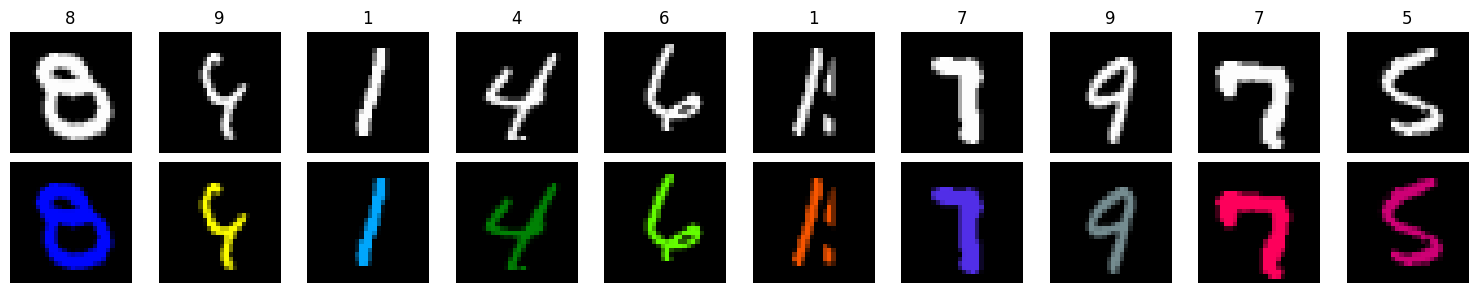

In [6]:
show_examples(dgp='dgp4')

Initiating Colored Mnist with dgp=dgp2, alpha=0.5, beta=0.2


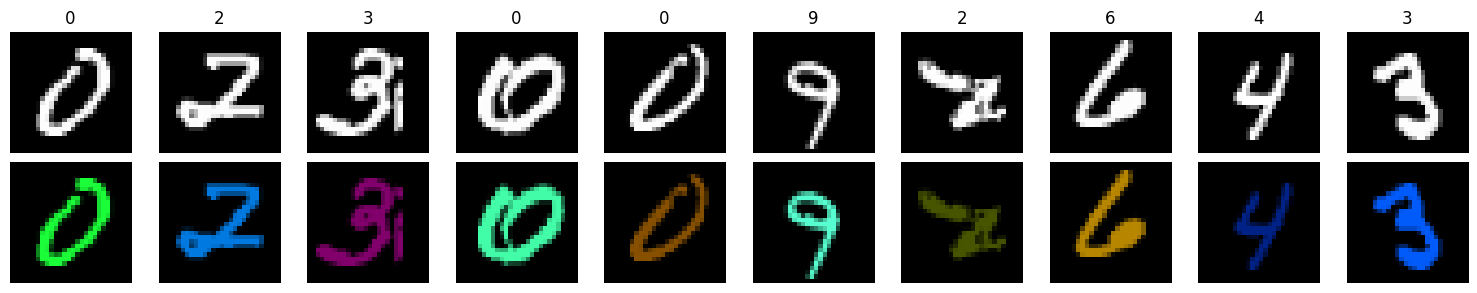

In [7]:
show_examples(dgp='dgp2')

In [8]:
# ---------------------------------------------------------------------
# Example usage
# ---------------------------------------------------------------------
train_ds = ColoredMNIST(root=".", train=True,  download=True)
test_ds  = ColoredMNIST(root=".", train=False, download=True)

train_ld = DataLoader(train_ds, batch_size=128, shuffle=True,  num_workers=4, pin_memory=True)
imgs, colored_imgs, labels, rgbs, zs, Rs = next(iter(train_ld))

print("Batch shapes:")
print("  images :", imgs.shape)      # (128, 3, 28, 28)
print("  labels :", labels.shape)    # (128,)
print("  rgbs   :", rgbs.shape)      # (128, 3)
print("  zs     :", zs.shape)        # (128, 3)
print("  Rs     :", Rs.shape)        # (128,)

Initiating Colored Mnist with dgp=dgp2, alpha=0.5, beta=0.2
Initiating Colored Mnist with dgp=dgp2, alpha=0.5, beta=0.2
Batch shapes:
  images : torch.Size([128, 1, 28, 28])
  labels : torch.Size([128])
  rgbs   : torch.Size([128, 3])
  zs     : torch.Size([128, 3])
  Rs     : torch.Size([128])


In [9]:
len(train_ds)

60000

In [10]:
it = 23
set_global_seeds(it)

# initializing alpha and beta right after the random seed to ensure consistency between train and evaluation
# that it is the same as the training alpha and beta
alpha = np.random.uniform(0.1, 0.7)
beta = np.random.uniform(0.1, 0.7)
print(f"{it}: alpha={alpha}, beta={beta}")

23: alpha=0.4103787303079536, beta=0.6681775622888885


In [11]:
# data
batch_size = 256
epochs = 50
arch = 'dense'
latent_dim = 32
dgp = 'dgp2'
dimz = 2 if dgp == 'dgp1' else 3
reg_weight = 1.0
indep_reg = linear_hsic
warm_start = False
subsample = -1
color_variable = ['instrument', 'rgb', 'reward', 'digit']
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
train_ds = ColoredMNIST(dgp=dgp, alpha=alpha, beta=beta, root=".", train=True,  download=True)
test_ds  = ColoredMNIST(dgp=dgp, alpha=alpha, beta=beta, root=".", train=False, download=True)

if subsample > 0:
    train_ds = get_stratified_subset_dataset(train_ds, int(subsample * 0.8), it)
    test_ds = get_stratified_subset_dataset(test_ds, int(subsample * 0.2), it)

train_ld = DataLoader(train_ds, batch_size, shuffle=True,  num_workers=10, pin_memory=True)
test_ld  = DataLoader(test_ds,  batch_size, shuffle=False, num_workers=10, pin_memory=True)

Initiating Colored Mnist with dgp=dgp2, alpha=0.4103787303079536, beta=0.6681775622888885
Initiating Colored Mnist with dgp=dgp2, alpha=0.4103787303079536, beta=0.6681775622888885


# Vanilla AutoEncoder on Colored MNIST

In [ ]:
ae, zp = train_ae(train_ld, test_ld, device, arch=arch, epochs=epochs, latent_dim=dimz,
                  vanilla=True, name="vanilla_ae.pt")

In [ ]:
Z, D, Y = get_iv_dataset(train_ld, ae, dimz)

In [14]:
u = tsls(Z, D, Y)
u

array([-0.9818156 ,  0.10542122,  0.15787561], dtype=float32)

[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    1.7s remaining:    1.7s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    1.7s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    1.5s remaining:    1.5s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    1.5s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    1.5s remaining:    1.5s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    1.5s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    1.5s remaining:    1.5s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    1.5s finished


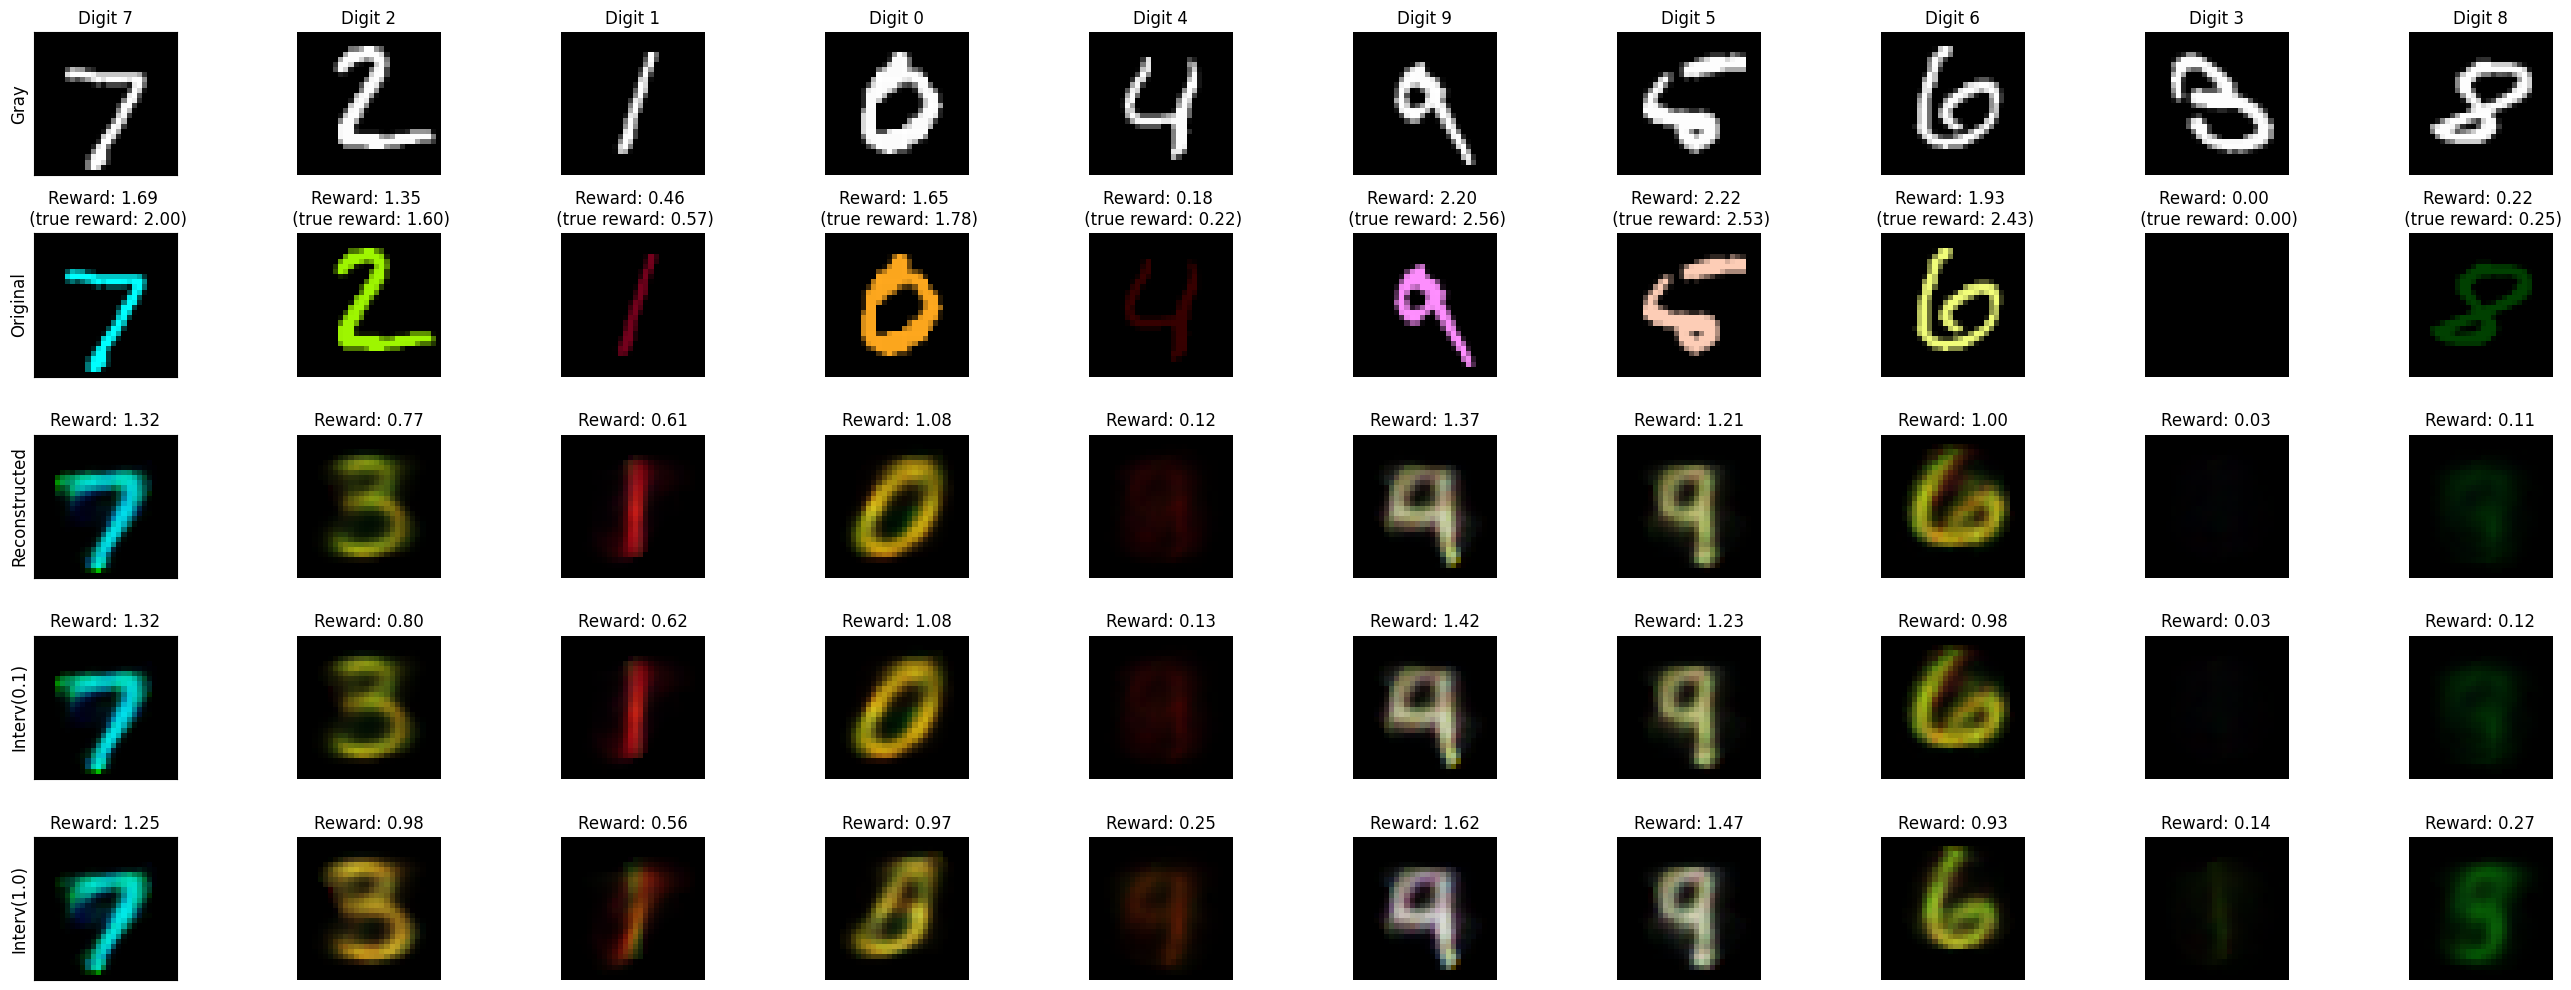

In [15]:
plot_examples(test_ds, ae, u, alpha1=0.1, figname="vanillaexamples.png")

In [16]:
perf_results, perf_mi_results = get_performance(test_ds, ae, u, variant=['kmeans', 'max_intensity'])
y_true, y_original, y_recon, y_interv, y_interv2 = perf_results
print(np.mean(y_true), np.mean(y_original), np.mean(y_recon), np.mean(y_interv), np.mean(y_interv2))
y_true, y_original, y_recon, y_interv, y_interv2 = perf_mi_results
print(np.mean(y_true), np.mean(y_original), np.mean(y_recon), np.mean(y_interv), np.mean(y_interv2))

Generating interventional image data


[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done 161 tasks      | elapsed:    0.1s
[Parallel(n_jobs=75)]: Done 803 tasks      | elapsed:    0.2s
[Parallel(n_jobs=75)]: Done 3575 tasks      | elapsed:    0.4s
[Parallel(n_jobs=75)]: Done 9211 tasks      | elapsed:    0.7s
[Parallel(n_jobs=75)]: Done 10000 out of 10000 | elapsed:    0.8s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done 138 tasks      | elapsed:    0.0s
[Parallel(n_jobs=75)]: Done 698 tasks      | elapsed:    0.1s
[Parallel(n_jobs=75)]: Done 3050 tasks      | elapsed:    0.2s
[Parallel(n_jobs=75)]: Done 9087 tasks      | elapsed:    0.5s
[Parallel(n_jobs=75)]: Done 10000 out of 10000 | elapsed:    0.6s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done 138 tasks      | elapsed:    0.0s
[Parallel(n_jobs=75)]: Done 698 tasks      | elapsed:    

1.5024508775336667 1.30712 0.8433994 0.8555214 0.9112448
1.5024508775336667 1.5018562 1.3270283 1.3462242 1.4408146


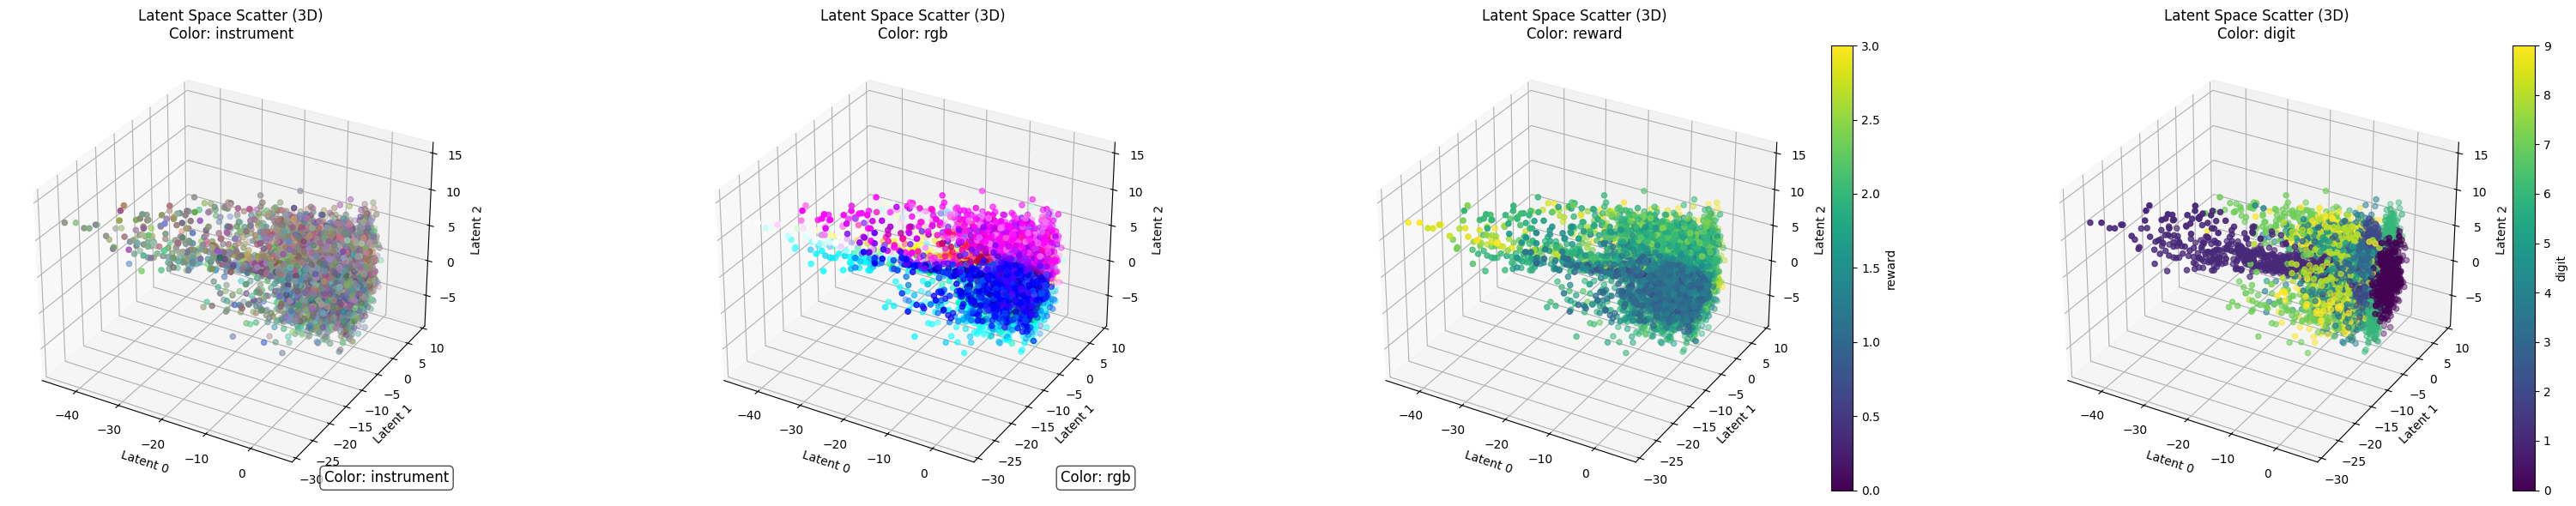

In [17]:
plot_latent_space_from_dataset(test_ds, ae, color_variable=color_variable)

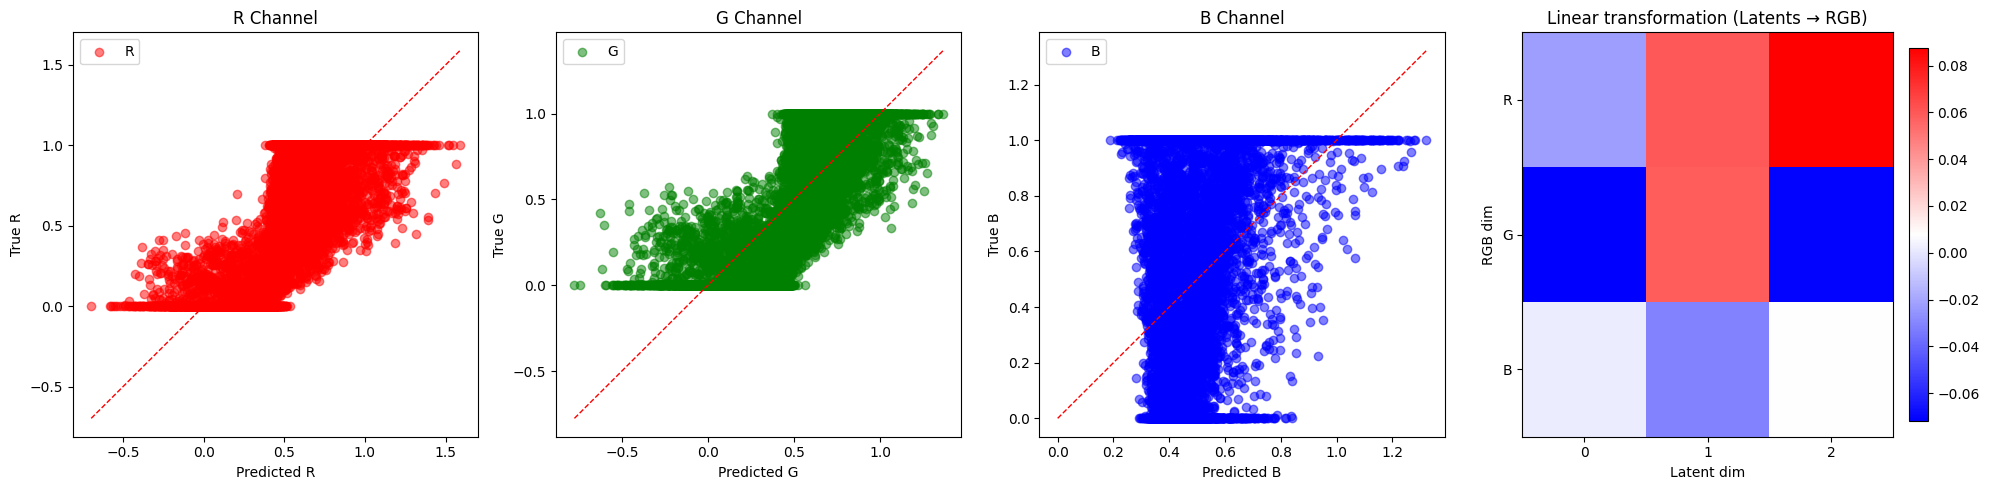

In [18]:
plot_linear_alignment_from_dataset(test_ds, ae, figname='latent_alignment_plot_vanilla.png')

# IGRL: Just Prediction of D from Z

In [19]:
ae, zp = train_ae(train_ld, test_ld, device, arch=arch, epochs=epochs, patience=10, dimz=dimz, latent_dim=dimz,
                  lambda_aux=reg_weight, lambda_reg1=None, lambda_reg2=None, lambda_reg3=None,
                  name="justZprediction.pt")

Training model with parameters: arch=dense, dimz=3, latent_dim=3, epochs=50, lr=0.001, vanilla=False, indep_reg=<function pairwise_hsic at 0x73acf2784220>, lambda_aux=1.0, lambda_reg1=None, lambda_reg2=None, lambda_reg3=None
Using a dense autoencoder
Ep  1/50  train 0.241658  val 0.128672
Ep  2/50  train 0.087079  val 0.058723
Ep  3/50  train 0.044209  val 0.036108
Ep  4/50  train 0.031867  val 0.031140
Ep  5/50  train 0.029251  val 0.028699
Ep  6/50  train 0.028439  val 0.028409
Ep  7/50  train 0.028006  val 0.028141
Ep  8/50  train 0.027798  val 0.028223
Ep  9/50  train 0.027630  val 0.027628
Ep 10/50  train 0.027439  val 0.027481
Ep 11/50  train 0.027231  val 0.027369
Ep 12/50  train 0.027133  val 0.027215
Ep 13/50  train 0.026996  val 0.027129
Ep 14/50  train 0.026912  val 0.027045
Ep 15/50  train 0.026797  val 0.026955
Ep 16/50  train 0.026659  val 0.026832
Ep 17/50  train 0.026673  val 0.026778
Ep 18/50  train 0.026577  val 0.026705
Ep 19/50  train 0.026466  val 0.026659
Ep 20/50

In [20]:
Z, D, Y = get_iv_dataset(train_ld, ae, dimz)

In [21]:
u = tsls(Z, D, Y)
u

array([-0.5718541, -0.3480489, -0.7428626], dtype=float32)

[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    1.3s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    1.4s remaining:    1.4s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    2.0s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    1.9s remaining:    1.9s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    3.2s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    1.1s remaining:    1.1s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    1.7s finished


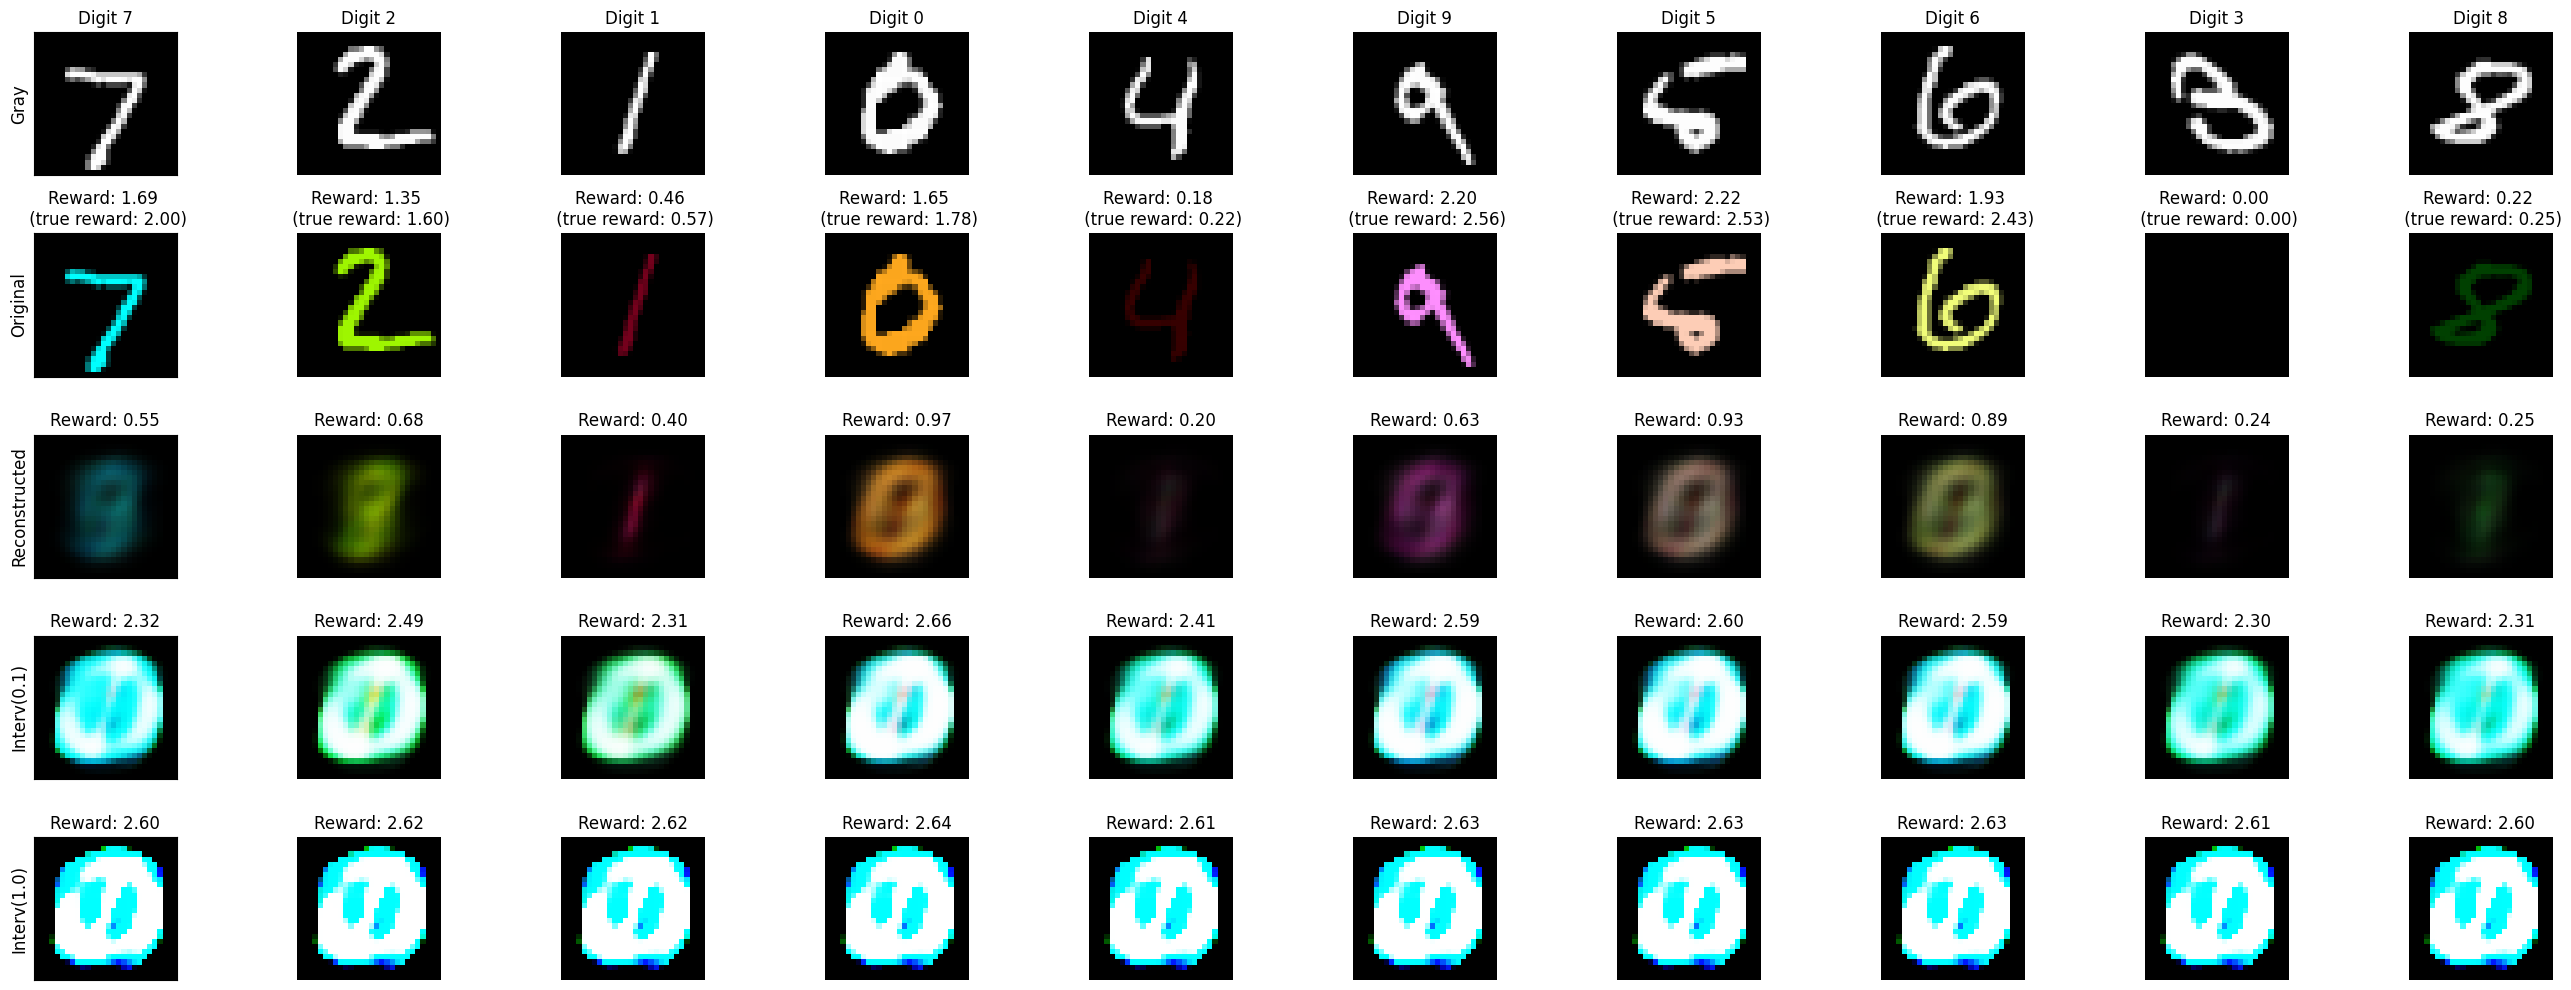

In [22]:
plot_examples(test_ds, ae, u, alpha1=0.1, figname="justZexamples.png")

In [23]:
perf_results = get_performance(test_ds, ae, u)
y_true, y_original, y_recon, y_interv, y_interv2 = perf_results
np.mean(y_true), np.mean(y_original), np.mean(y_recon), np.mean(y_interv), np.mean(y_interv2)

Generating interventional image data


[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   1 out of   1 | elapsed:    0.0s finished
[Parallel(n_jobs=75)]: Done 144 tasks      | elapsed:    0.0s
[Parallel(n_jobs=75)]: Done 750 tasks      | elapsed:    0.1s
[Parallel(n_jobs=75)]: Done 3370 tasks      | elapsed:    0.3s
[Parallel(n_jobs=75)]: Done 9186 tasks      | elapsed:    0.5s
[Parallel(n_jobs=75)]: Done 9851 out of 10000 | elapsed:    0.6s remaining:    0.0s
[Parallel(n_jobs=75)]: Done 10000 out of 10000 | elapsed:    0.7s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done 138 tasks      | elapsed:    0.0s
[Parallel(n_jobs=75)]: Done 698 tasks      | elapsed:    0.1s
[Parallel(n_jobs=75)]: Done 3050 tasks      | elapsed:    0.2s
[Parallel(n_jobs=75)]: Done 8901 tasks      | elapsed:    0.4s
[Parallel(n_jobs=75)]: Done 10000 out of 10000 | elapsed:    0.5s finished
[Parallel(n_jobs=75)]: Using backend Loky

(np.float64(1.5024508775336667),
 np.float32(1.30712),
 np.float32(0.6234512),
 np.float32(2.5758657),
 np.float32(2.6179874))

In [24]:
perf_results = get_performance(test_ds, ae, u, variant='max_intensity')
y_true, y_original, y_recon, y_interv, y_interv2 = perf_results
np.mean(y_true), np.mean(y_original), np.mean(y_recon), np.mean(y_interv), np.mean(y_interv2)

Generating interventional image data


(np.float64(1.5024508775336667),
 np.float32(1.5018562),
 np.float32(1.0025594),
 np.float32(2.9996188),
 np.float32(3.0))

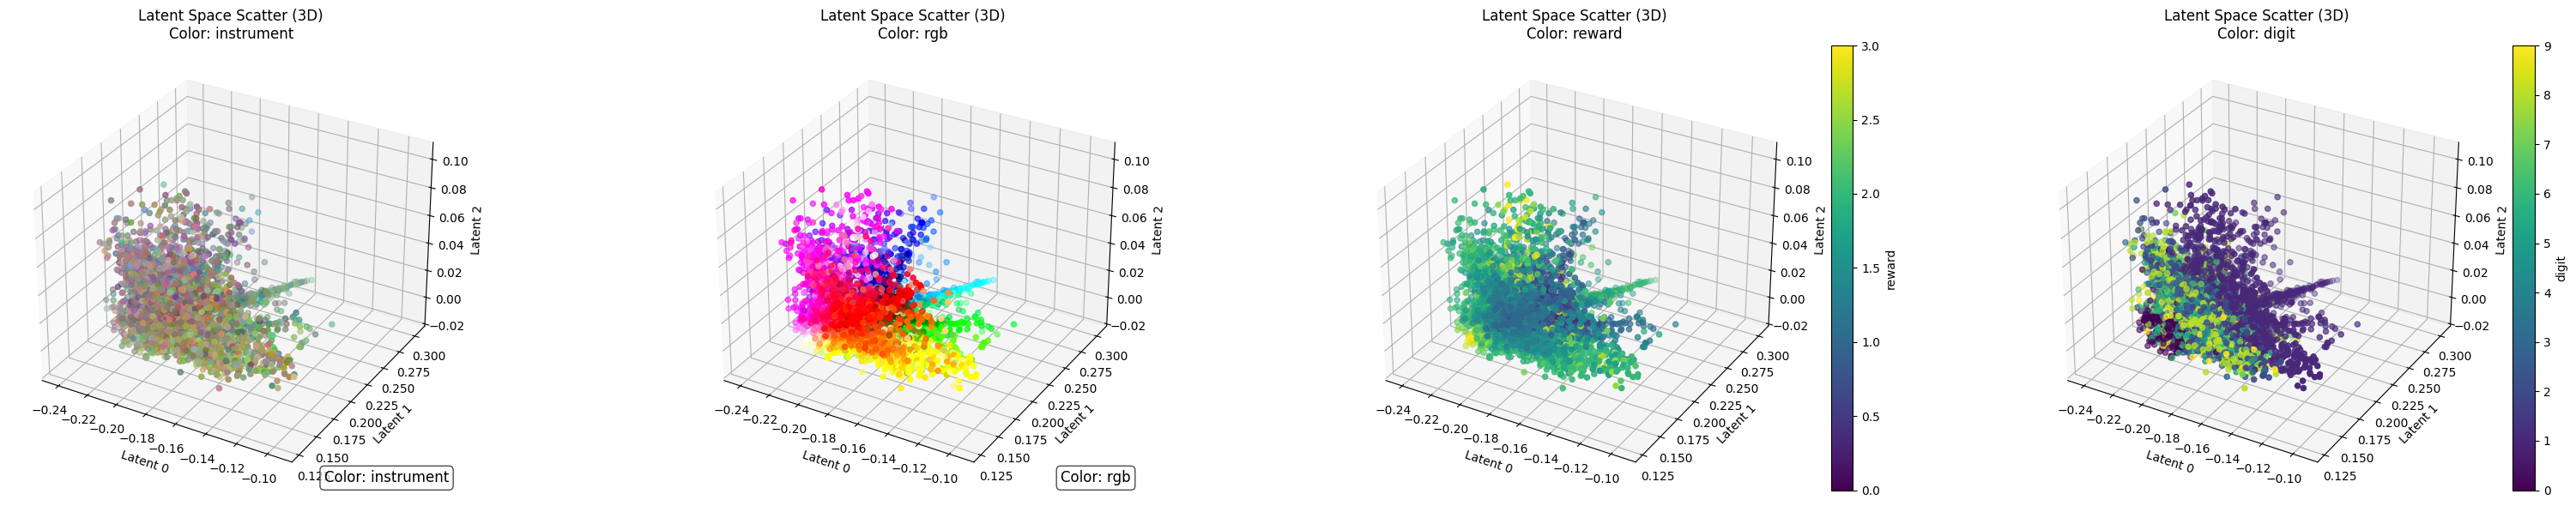

In [25]:
plot_latent_space_from_dataset(test_ds, ae, color_variable=color_variable)

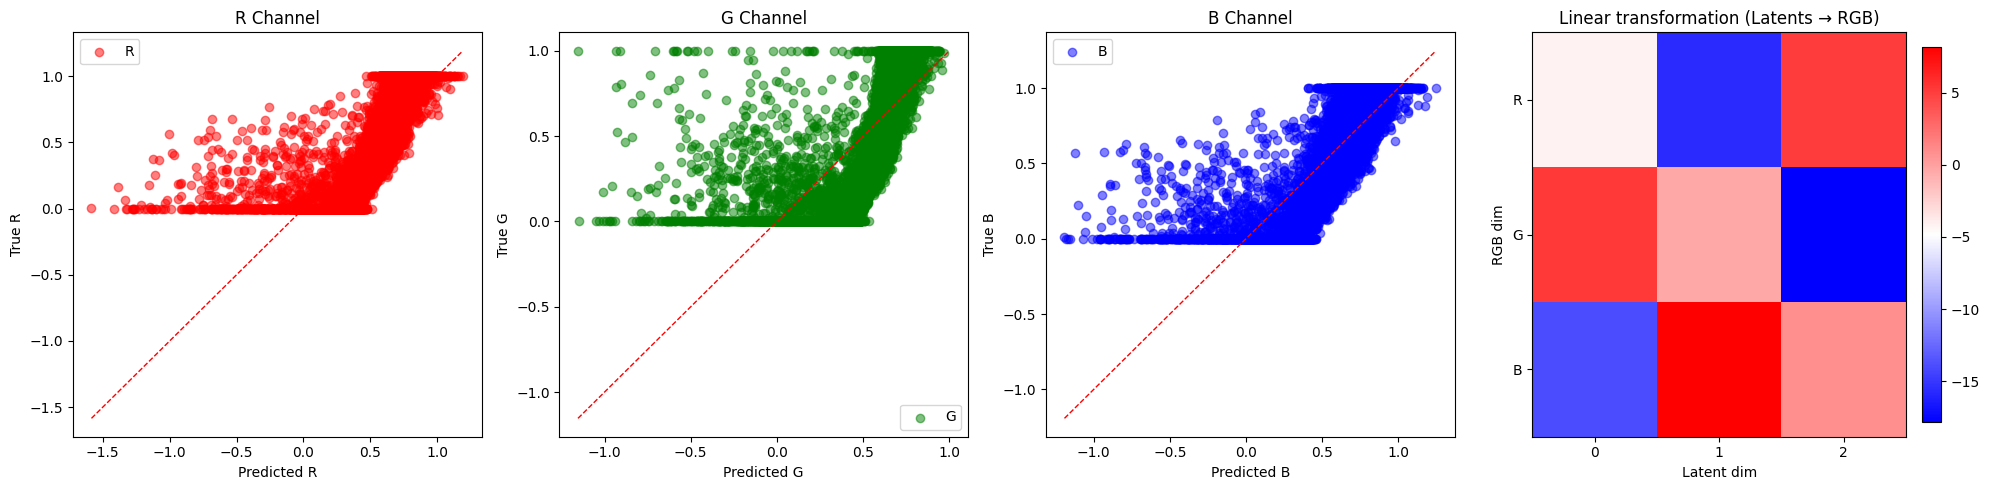

In [26]:
plot_linear_alignment_from_dataset(test_ds, ae, figname='latent_alignment_plot_justZ.png')

# IGRL: Adding also D-AZ independent of Z

In [27]:
ae, zp = train_ae(train_ld, test_ld, device, arch=arch, epochs=epochs, patience=10, dimz=dimz, latent_dim=dimz, indep_reg=indep_reg,
                  lambda_reg1=reg_weight, lambda_reg2=None, lambda_reg3=None,
                  name="IRAE1.pt")

Training model with parameters: arch=dense, dimz=3, latent_dim=3, epochs=50, lr=0.001, vanilla=False, indep_reg=<function linear_hsic at 0x73acf2784180>, lambda_aux=1.0, lambda_reg1=1.0, lambda_reg2=None, lambda_reg3=None
Using a dense autoencoder
Ep  1/50  train 0.291528  val 0.137830
Ep  2/50  train 0.082041  val 0.049688
Ep  3/50  train 0.037256  val 0.031808
Ep  4/50  train 0.029560  val 0.028937
Ep  5/50  train 0.028222  val 0.028244
Ep  6/50  train 0.027750  val 0.027890
Ep  7/50  train 0.027462  val 0.027573
Ep  8/50  train 0.027303  val 0.027397
Ep  9/50  train 0.027095  val 0.027229
Ep 10/50  train 0.026976  val 0.027326
Ep 11/50  train 0.026843  val 0.026994
Ep 12/50  train 0.026746  val 0.026890
Ep 13/50  train 0.026641  val 0.026791
Ep 14/50  train 0.026557  val 0.026726
Ep 15/50  train 0.026477  val 0.026667
Ep 16/50  train 0.026415  val 0.026592
Ep 17/50  train 0.026358  val 0.026511
Ep 18/50  train 0.026305  val 0.026491
Ep 19/50  train 0.026250  val 0.026419
Ep 20/50  t

In [28]:
Z, D, Y = get_iv_dataset(train_ld, ae, dimz)

In [29]:
u = tsls(Z, D, Y)
u

array([-0.7956882 ,  0.41852325, -0.4378567 ], dtype=float32)

[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    1.3s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    1.3s remaining:    1.3s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    2.7s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    1.1s remaining:    1.1s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    1.4s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   1 out of   1 | elapsed:    0.0s finished
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    1.8s finished


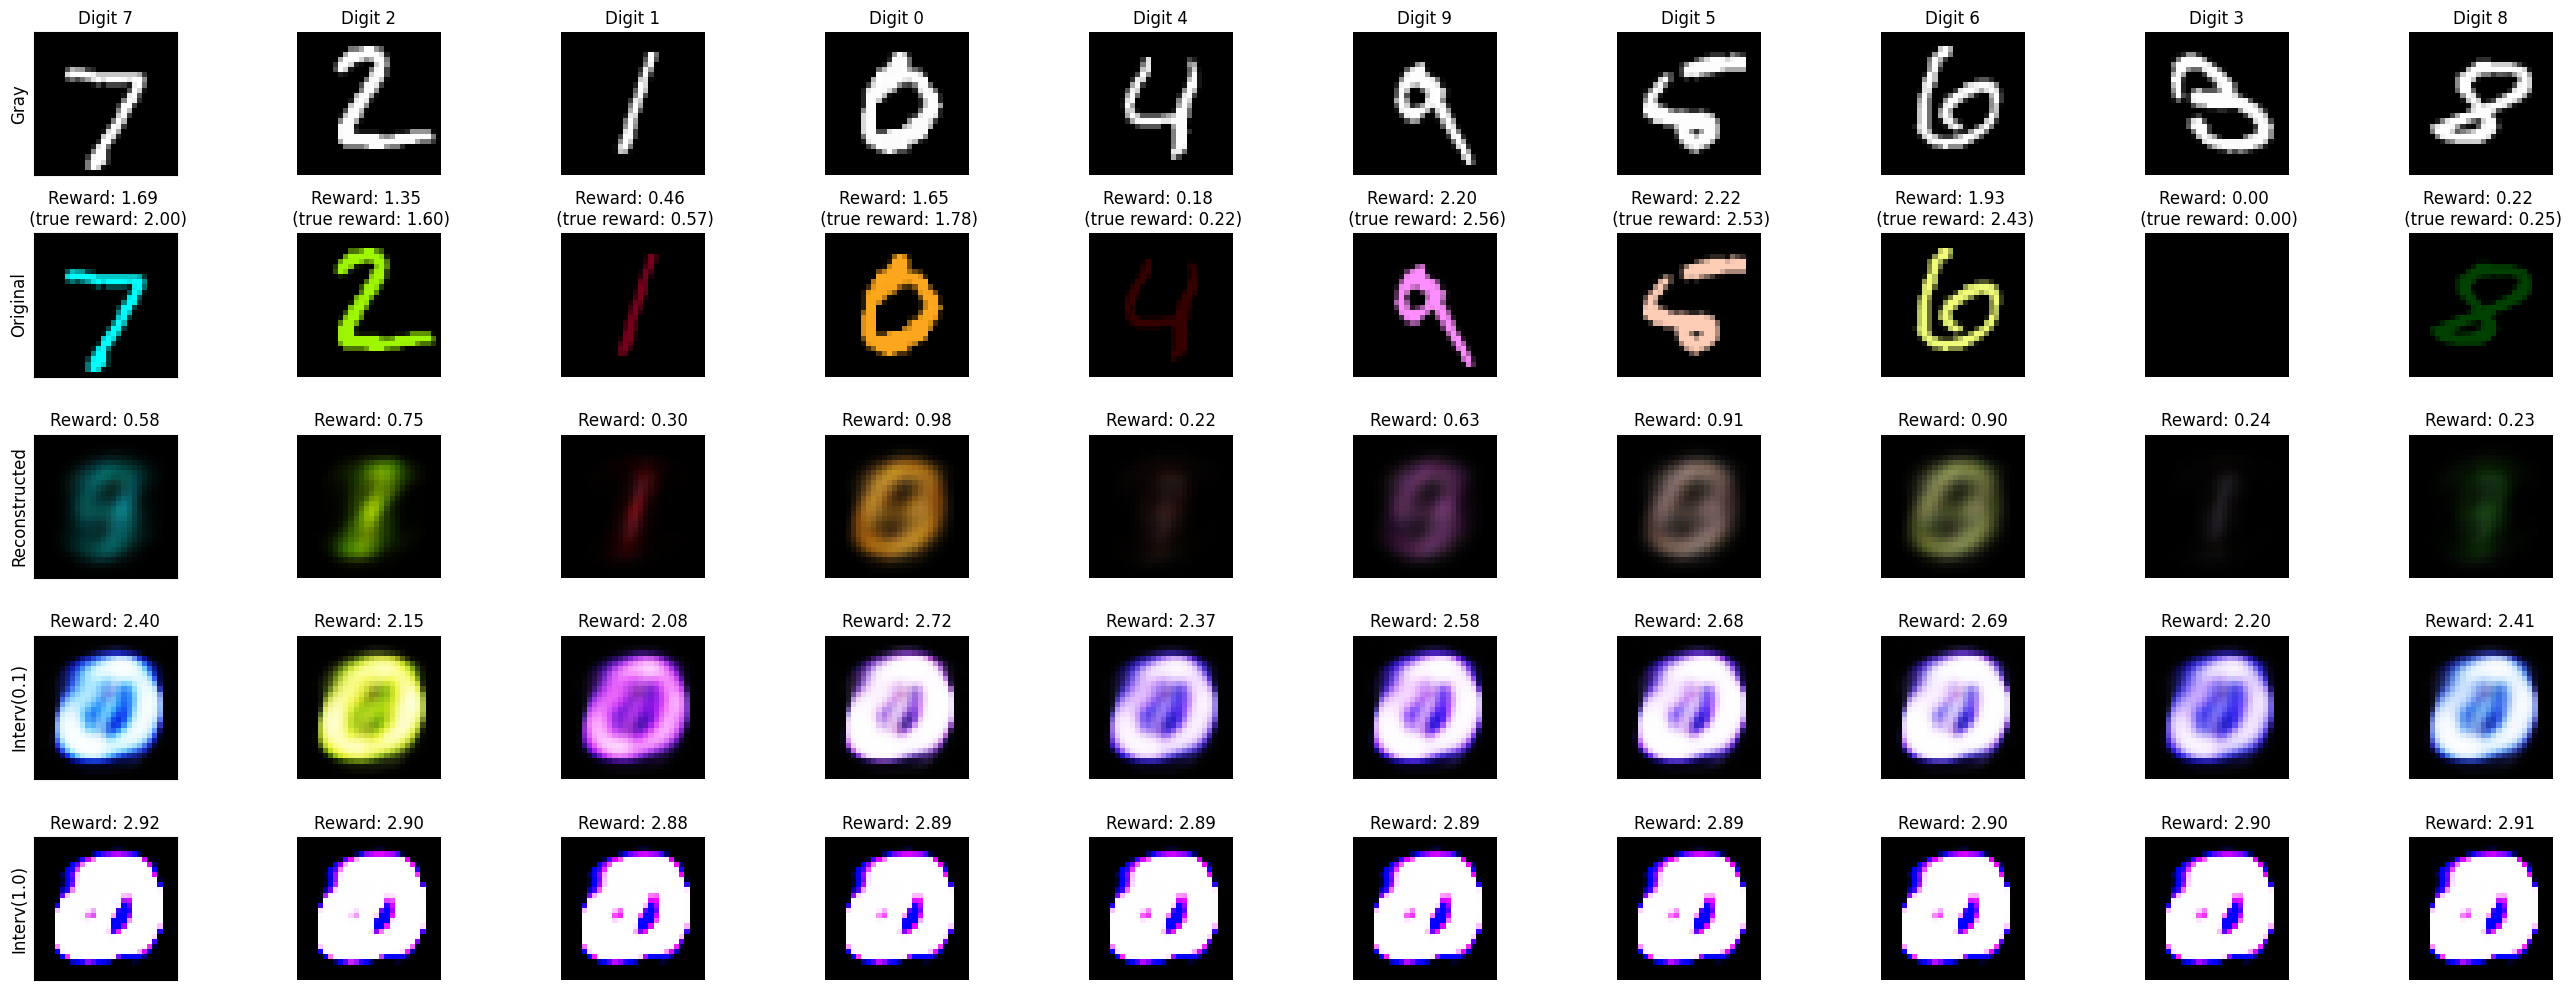

In [30]:
plot_examples(test_ds, ae, u, alpha1=0.1, figname="irae1examples.png")

In [31]:
perf_results = get_performance(test_ds, ae, u)
y_true, y_original, y_recon, y_interv, y_interv2 = perf_results
np.mean(y_true), np.mean(y_original), np.mean(y_recon), np.mean(y_interv), np.mean(y_interv2)

Generating interventional image data


[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   1 out of   1 | elapsed:    0.0s finished
[Parallel(n_jobs=75)]: Done 139 tasks      | elapsed:    0.1s
[Parallel(n_jobs=75)]: Done 735 tasks      | elapsed:    0.1s
[Parallel(n_jobs=75)]: Done 3307 tasks      | elapsed:    0.2s
[Parallel(n_jobs=75)]: Done 8951 tasks      | elapsed:    0.7s
[Parallel(n_jobs=75)]: Done 9851 out of 10000 | elapsed:    0.7s remaining:    0.0s
[Parallel(n_jobs=75)]: Done 10000 out of 10000 | elapsed:    0.7s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done 138 tasks      | elapsed:    0.0s
[Parallel(n_jobs=75)]: Done 698 tasks      | elapsed:    0.1s
[Parallel(n_jobs=75)]: Done 3050 tasks      | elapsed:    0.2s
[Parallel(n_jobs=75)]: Done 8808 tasks      | elapsed:    0.4s
[Parallel(n_jobs=75)]: Done 10000 out of 10000 | elapsed:    0.5s finished
[Parallel(n_jobs=75)]: Using backend Loky

(np.float64(1.5024508775336667),
 np.float32(1.30712),
 np.float32(0.6316456),
 np.float32(2.7177076),
 np.float32(2.898035))

In [32]:
perf_results = get_performance(test_ds, ae, u, variant='max_intensity')
y_true, y_original, y_recon, y_interv, y_interv2 = perf_results
np.mean(y_true), np.mean(y_original), np.mean(y_recon), np.mean(y_interv), np.mean(y_interv2)

Generating interventional image data


(np.float64(1.5024508775336667),
 np.float32(1.5018562),
 np.float32(1.0544868),
 np.float32(2.9980297),
 np.float32(3.0))

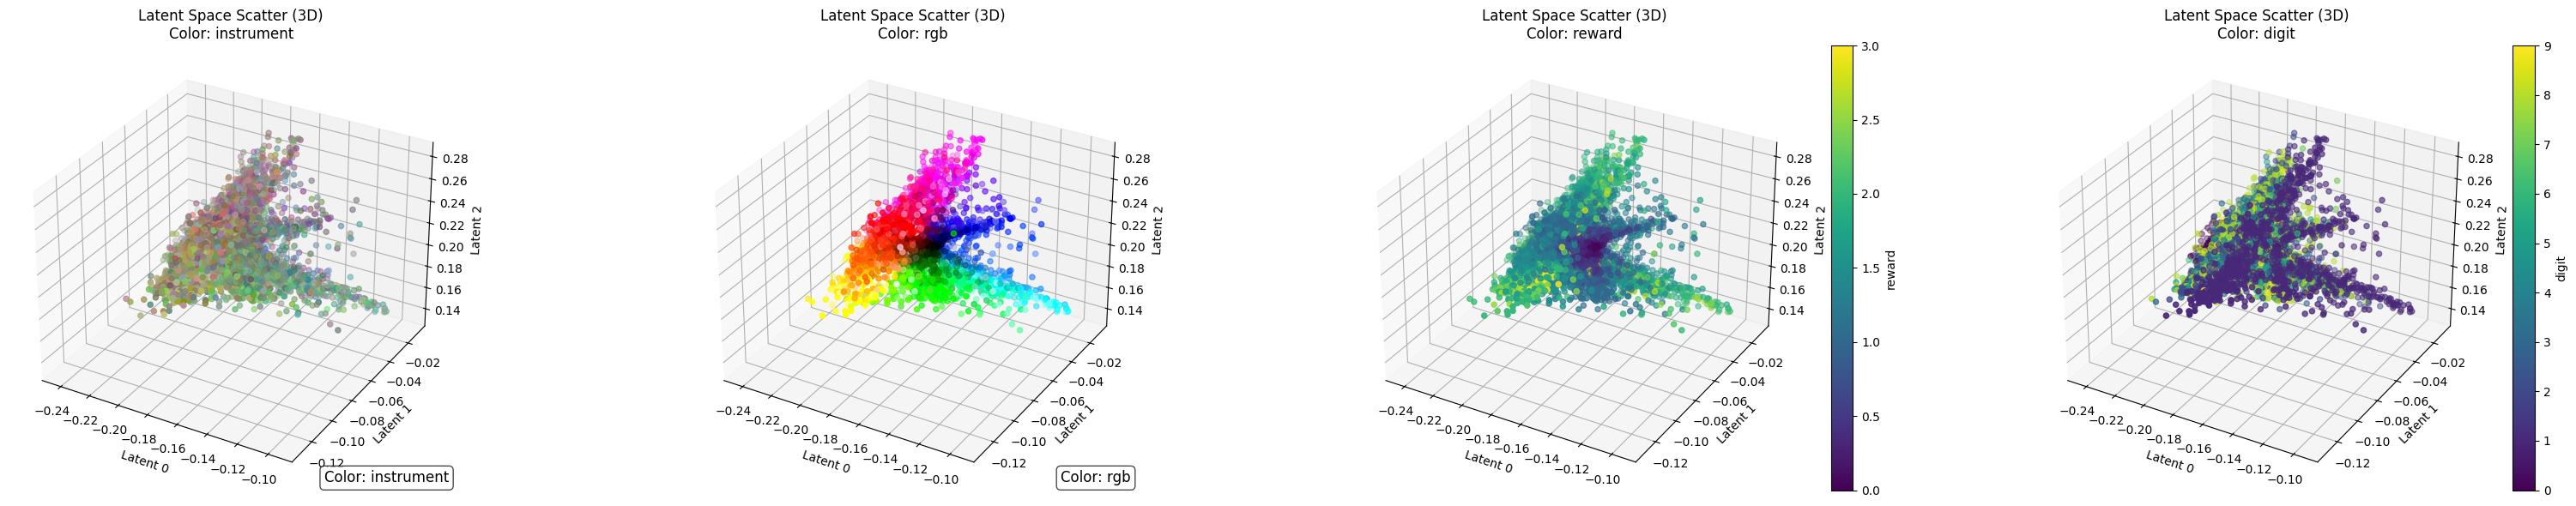

In [33]:
plot_latent_space_from_dataset(test_ds, ae, color_variable=color_variable)

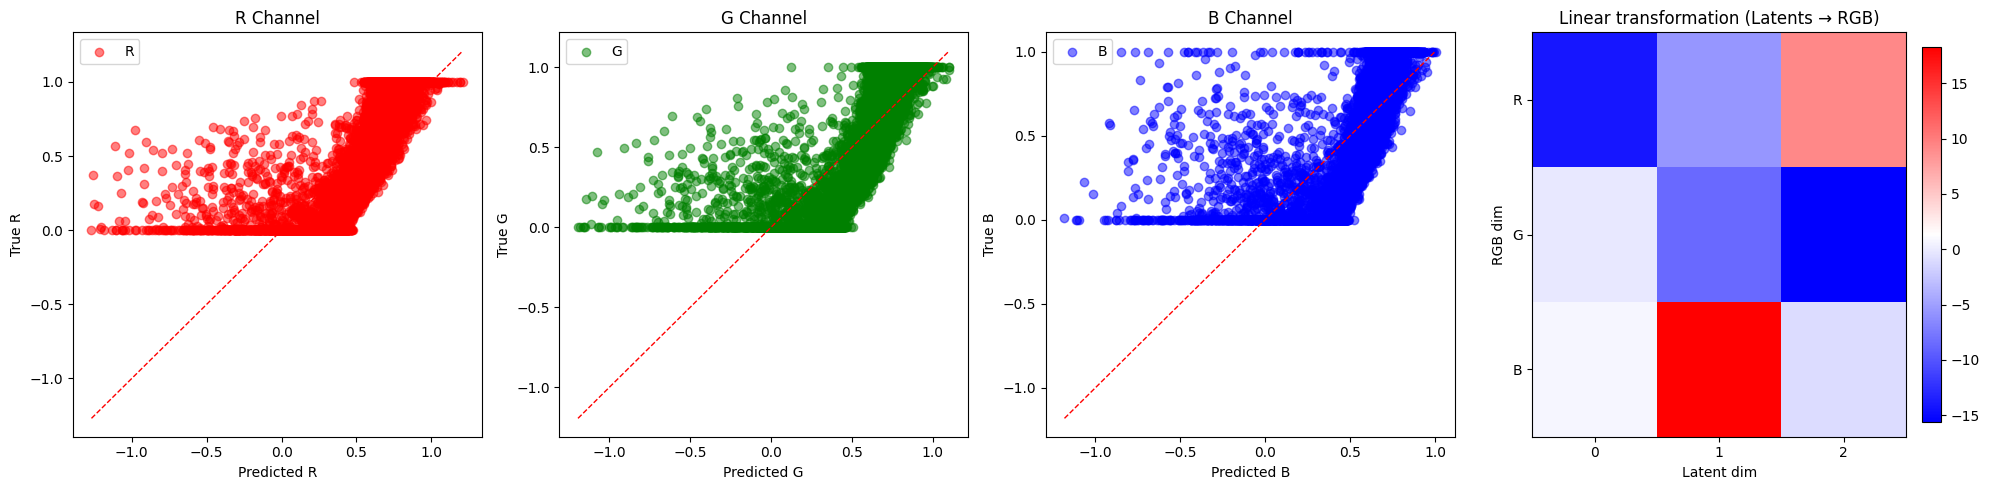

In [34]:
plot_linear_alignment_from_dataset(test_ds, ae, figname='latent_alignment_plot_irae1.png')

# Adding Z independent of V

In [35]:
irae2 = None
if warm_start:
    if arch == 'dense':
        irae1 = Autoencoder(latent_dim=dimz).to(device)
        irae1.load_state_dict(torch.load("IRAE1.pt", map_location=device)['ae_state'])
        irae2 = Autoencoder(latent_dim=latent_dim).to(device)
        init_big_from_small(irae1, irae2, dimz)
    else:
        irae1 = ConvAutoencoder(latent_dim=dimz).to(device)
        irae1.load_state_dict(torch.load("IRAE1.pt", map_location=device)['ae_state'])
        irae2 = ConvAutoencoder(latent_dim=latent_dim).to(device)
        init_big_from_small_conv(irae1, irae2, dimz)

In [36]:
ae, zp = train_ae(train_ld, test_ld, device, arch=arch, dimz=dimz, epochs=epochs, patience=10, latent_dim=latent_dim, indep_reg=indep_reg,
                  lambda_reg1=reg_weight, lambda_reg2=reg_weight, lambda_reg3=None,
                  name="IRAE2.pt", warm_start=irae2)

Training model with parameters: arch=dense, dimz=3, latent_dim=32, epochs=50, lr=0.001, vanilla=False, indep_reg=<function linear_hsic at 0x73acf2784180>, lambda_aux=1.0, lambda_reg1=1.0, lambda_reg2=1.0, lambda_reg3=None
Using a dense autoencoder
Ep  1/50  train 0.494393  val 0.244811
Ep  2/50  train 0.143489  val 0.076901
Ep  3/50  train 0.047682  val 0.031688
Ep  4/50  train 0.024523  val 0.021100
Ep  5/50  train 0.018522  val 0.017323
Ep  6/50  train 0.015983  val 0.015295
Ep  7/50  train 0.014369  val 0.014023
Ep  8/50  train 0.013255  val 0.012875
Ep  9/50  train 0.012291  val 0.012047
Ep 10/50  train 0.011650  val 0.011452
Ep 11/50  train 0.011077  val 0.010888
Ep 12/50  train 0.010551  val 0.010387
Ep 13/50  train 0.010156  val 0.010094
Ep 14/50  train 0.009837  val 0.009700
Ep 15/50  train 0.009441  val 0.009268
Ep 16/50  train 0.009154  val 0.008986
Ep 17/50  train 0.008909  val 0.009132
Ep 18/50  train 0.008693  val 0.008586
Ep 19/50  train 0.008471  val 0.008618
Ep 20/50  t

In [37]:
Z, D, Y = get_iv_dataset(train_ld, ae, dimz)

In [38]:
u = tsls(Z, D, Y)
u

array([0.04201231, 0.04530882, 0.9980892 ], dtype=float32)

[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    1.0s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    1.0s remaining:    1.0s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    1.1s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   1 out of   1 | elapsed:    0.0s finished
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    0.4s remaining:    0.4s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    3.4s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    0.3s remaining:    0.3s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    1.7s finished


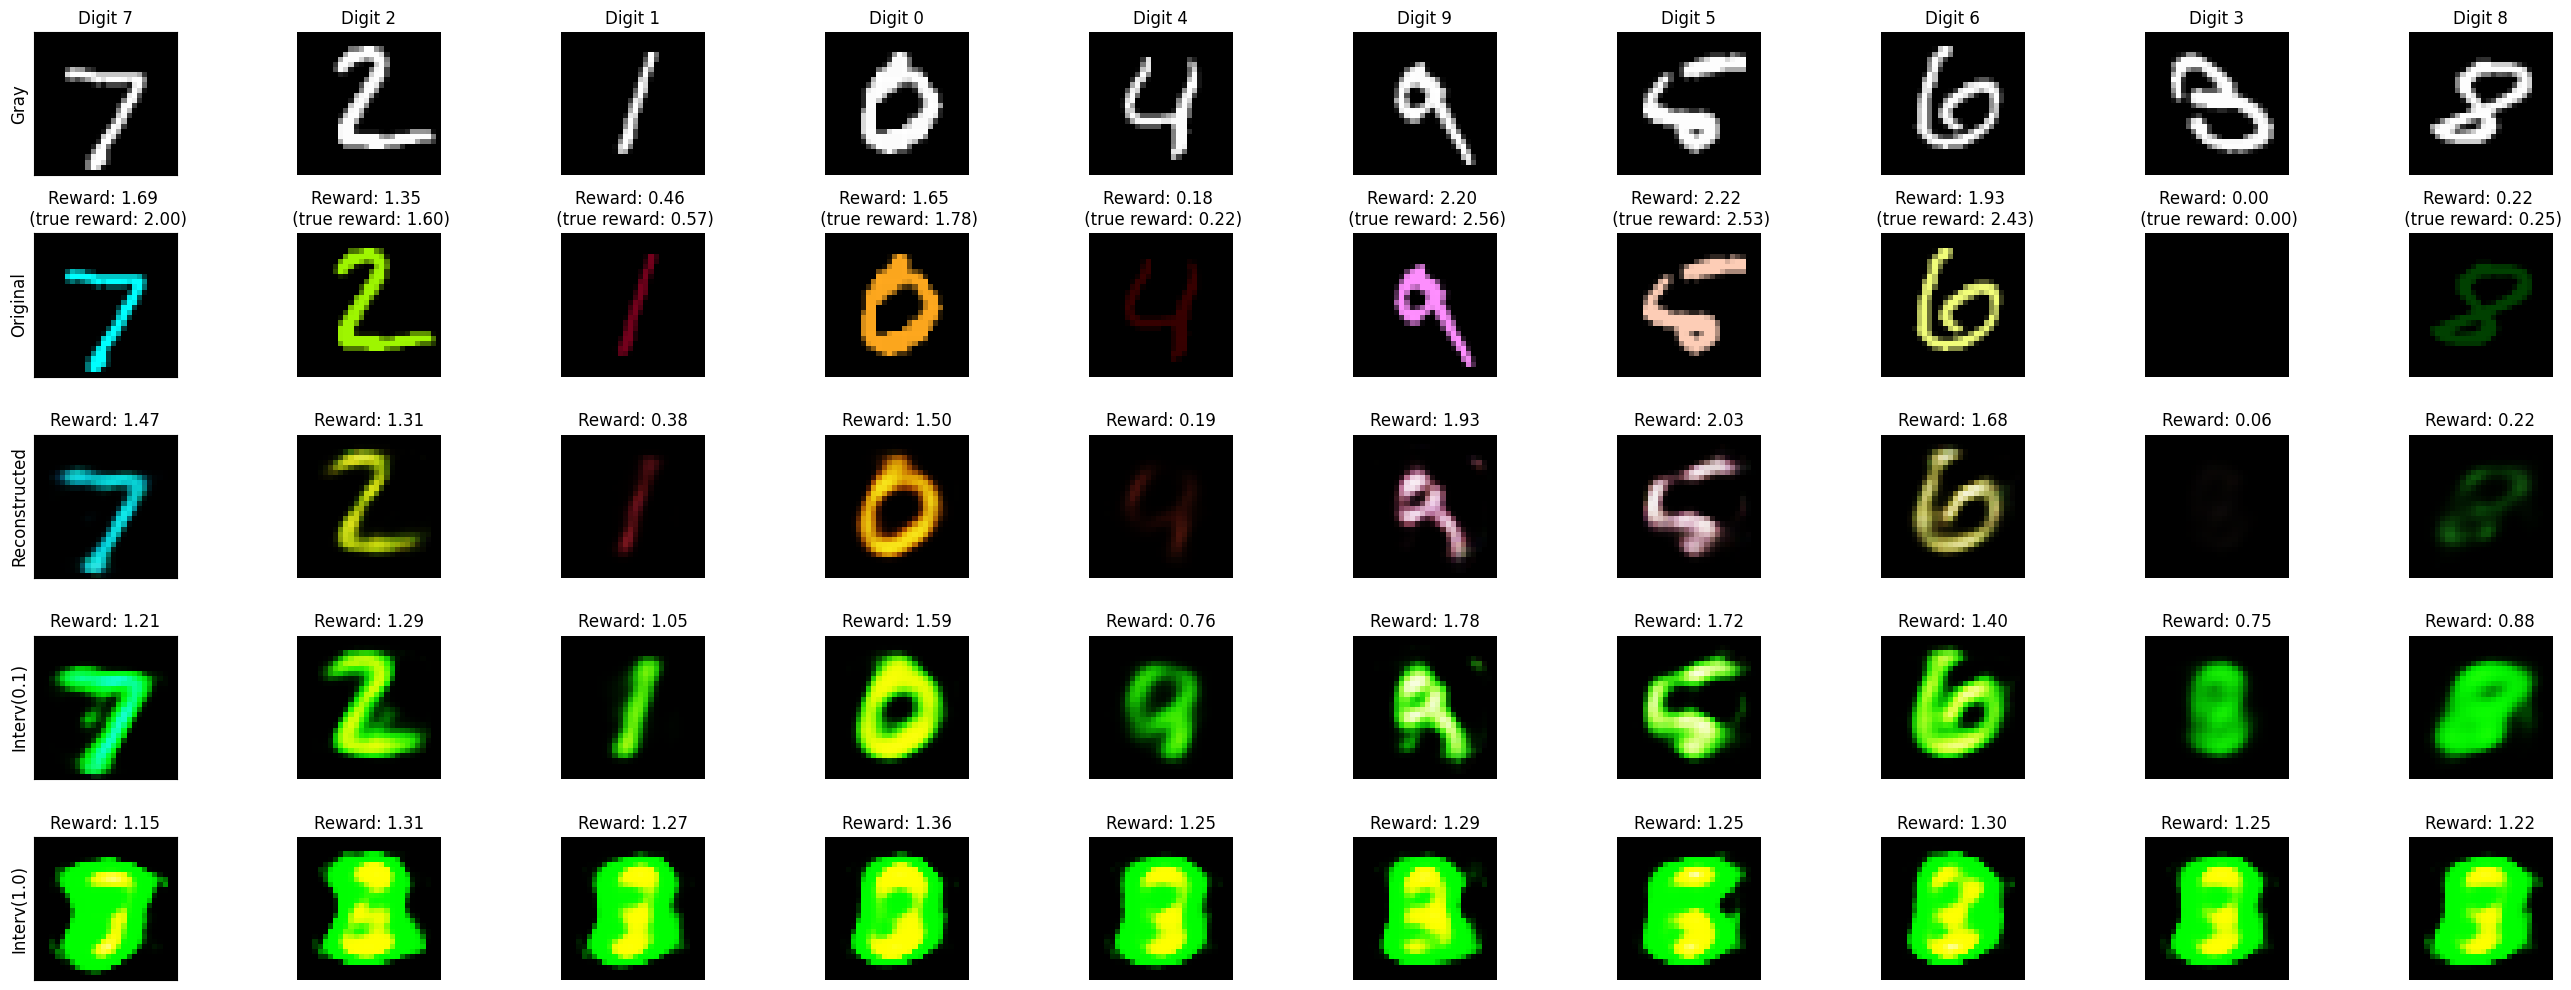

In [39]:
plot_examples(test_ds, ae, u, alpha1=0.1, figname="irae2examples.png")

In [40]:
perf_results = get_performance(test_ds, ae, u)
y_true, y_original, y_recon, y_interv, y_interv2 = perf_results
np.mean(y_true), np.mean(y_original), np.mean(y_recon), np.mean(y_interv), np.mean(y_interv2)

Generating interventional image data


[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   1 out of   1 | elapsed:    0.0s finished
[Parallel(n_jobs=75)]: Done 139 tasks      | elapsed:    0.1s
[Parallel(n_jobs=75)]: Done 736 tasks      | elapsed:    0.1s
[Parallel(n_jobs=75)]: Done 3288 tasks      | elapsed:    0.3s
[Parallel(n_jobs=75)]: Done 9117 tasks      | elapsed:    0.5s
[Parallel(n_jobs=75)]: Done 9851 out of 10000 | elapsed:    0.5s remaining:    0.0s
[Parallel(n_jobs=75)]: Done 10000 out of 10000 | elapsed:    0.7s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done 138 tasks      | elapsed:    0.0s
[Parallel(n_jobs=75)]: Done 698 tasks      | elapsed:    0.1s
[Parallel(n_jobs=75)]: Done 3050 tasks      | elapsed:    0.2s
[Parallel(n_jobs=75)]: Done 8808 tasks      | elapsed:    0.4s
[Parallel(n_jobs=75)]: Done 10000 out of 10000 | elapsed:    0.5s finished
[Parallel(n_jobs=75)]: Using backend Loky

(np.float64(1.5024508775336667),
 np.float32(1.30712),
 np.float32(1.145594),
 np.float32(1.2450877),
 np.float32(1.2679504))

In [41]:
perf_results = get_performance(test_ds, ae, u, variant='max_intensity')
y_true, y_original, y_recon, y_interv, y_interv2 = perf_results
np.mean(y_true), np.mean(y_original), np.mean(y_recon), np.mean(y_interv), np.mean(y_interv2)

Generating interventional image data


(np.float64(1.5024508775336667),
 np.float32(1.5018562),
 np.float32(1.7356807),
 np.float32(2.1220117),
 np.float32(2.306168))

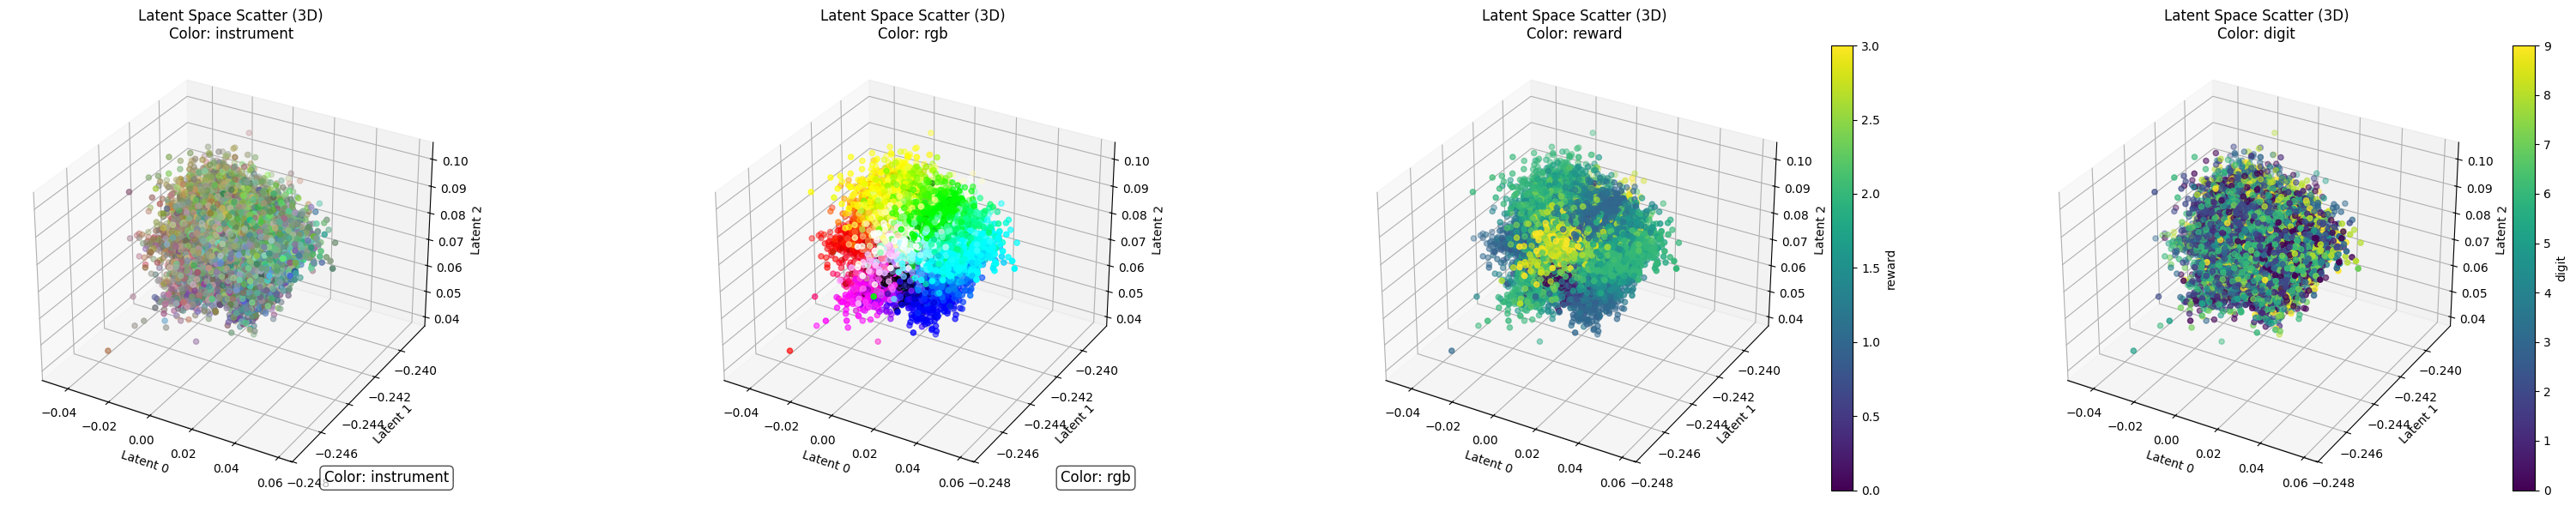

In [42]:
plot_latent_space_from_dataset(test_ds, ae, color_variable=color_variable)

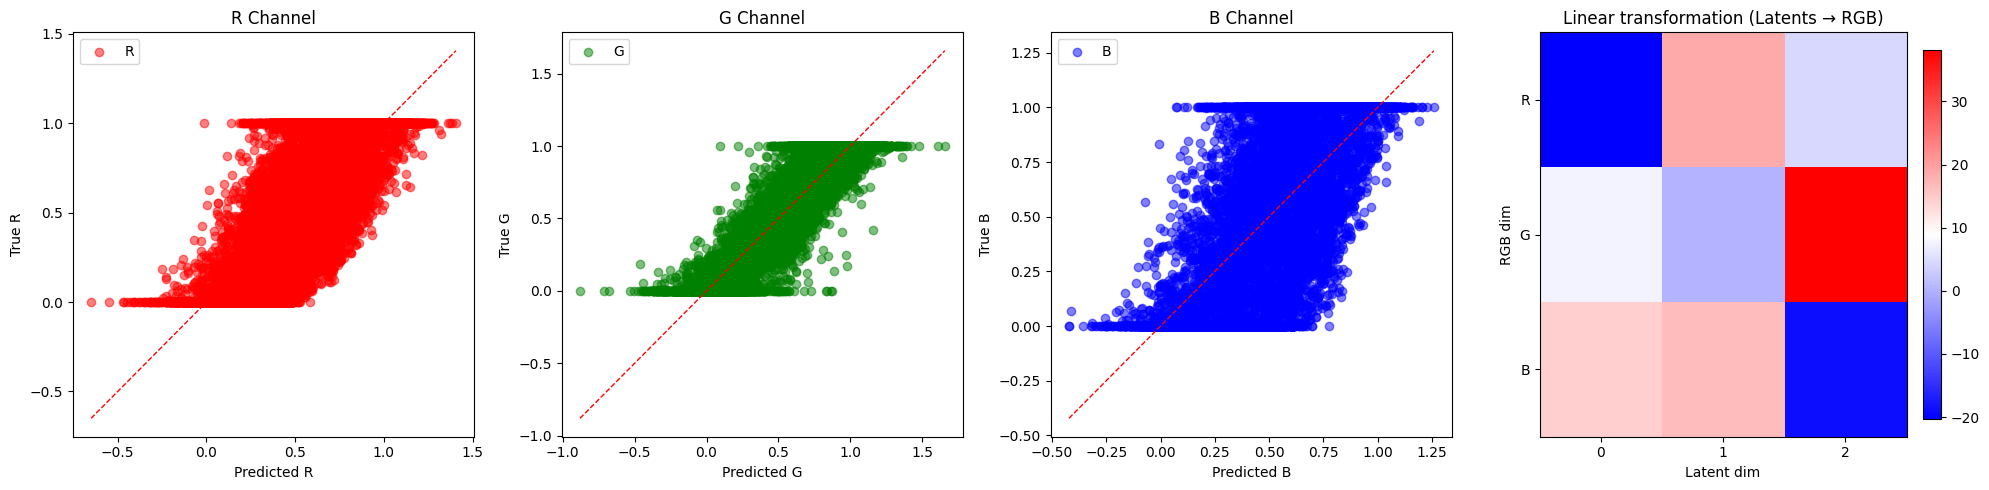

In [43]:
plot_linear_alignment_from_dataset(test_ds, ae, figname='latent_alignment_plot_irae2.png')

# Adding also D independent of V

In [13]:
irae3 = None
if warm_start:
    if arch == 'dense':
        irae1 = Autoencoder(latent_dim=dimz).to(device)
        irae1.load_state_dict(torch.load("IRAE1.pt", map_location=device)['ae_state'])
        irae3 = Autoencoder(latent_dim=latent_dim).to(device)
        init_big_from_small(irae1, irae3, dimz)
    else:
        irae1 = ConvAutoencoder(latent_dim=dimz).to(device)
        irae1.load_state_dict(torch.load("IRAE1.pt", map_location=device)['ae_state'])
        irae3 = ConvAutoencoder(latent_dim=latent_dim).to(device)
        init_big_from_small_conv(irae1, irae3, dimz)

In [14]:
from independence import linear_hsic
ae, zp = train_ae(train_ld, test_ld, device, arch=arch, dimz=dimz, epochs=epochs, patience=10, latent_dim=latent_dim, indep_reg=indep_reg,
                  lambda_reg1=reg_weight, lambda_reg2=reg_weight, lambda_reg3=reg_weight, noise_std=0.0,
                  name="IRAE3.pt", warm_start=irae3)

Training model with parameters: arch=dense, dimz=3, latent_dim=32, epochs=50, lr=0.001, vanilla=False, indep_reg=<function linear_hsic at 0x72db824a6520>, jindep_reg=<function pairwise_joint_hsic at 0x72db824a68e0>, lambda_aux=1.0, lambda_reg1=1.0, lambda_reg2=1.0, lambda_reg3=1.0, noise_std=0.0
Using a dense autoencoder
Ep  1/50  train 0.662566  val 0.347727
Ep  2/50  train 0.209057  val 0.121096
Ep  3/50  train 0.071270  val 0.044372
Ep  4/50  train 0.029683  val 0.023166
Ep  5/50  train 0.018820  val 0.017250
Ep  6/50  train 0.015663  val 0.015126
Ep  7/50  train 0.014147  val 0.013812
Ep  8/50  train 0.013081  val 0.012854
Ep  9/50  train 0.012255  val 0.011995
Ep 10/50  train 0.011567  val 0.011542
Ep 11/50  train 0.010984  val 0.010772
Ep 12/50  train 0.010454  val 0.010280
Ep 13/50  train 0.010030  val 0.010296
Ep 14/50  train 0.009693  val 0.009488
Ep 15/50  train 0.009359  val 0.009117
Ep 16/50  train 0.009135  val 0.009073
Ep 17/50  train 0.008823  val 0.008614
Ep 18/50  trai

In [15]:
Z, D, Y = get_iv_dataset(train_ld, ae, dimz)

In [16]:
u = tsls(Z, D, Y)
u

array([ 0.7075723 , -0.06528524, -0.70361876], dtype=float32)

[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    1.8s remaining:    1.8s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    1.8s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    1.6s remaining:    1.6s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    1.6s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    1.6s remaining:    1.6s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    1.6s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    1.6s remaining:    1.6s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    1.6s finished


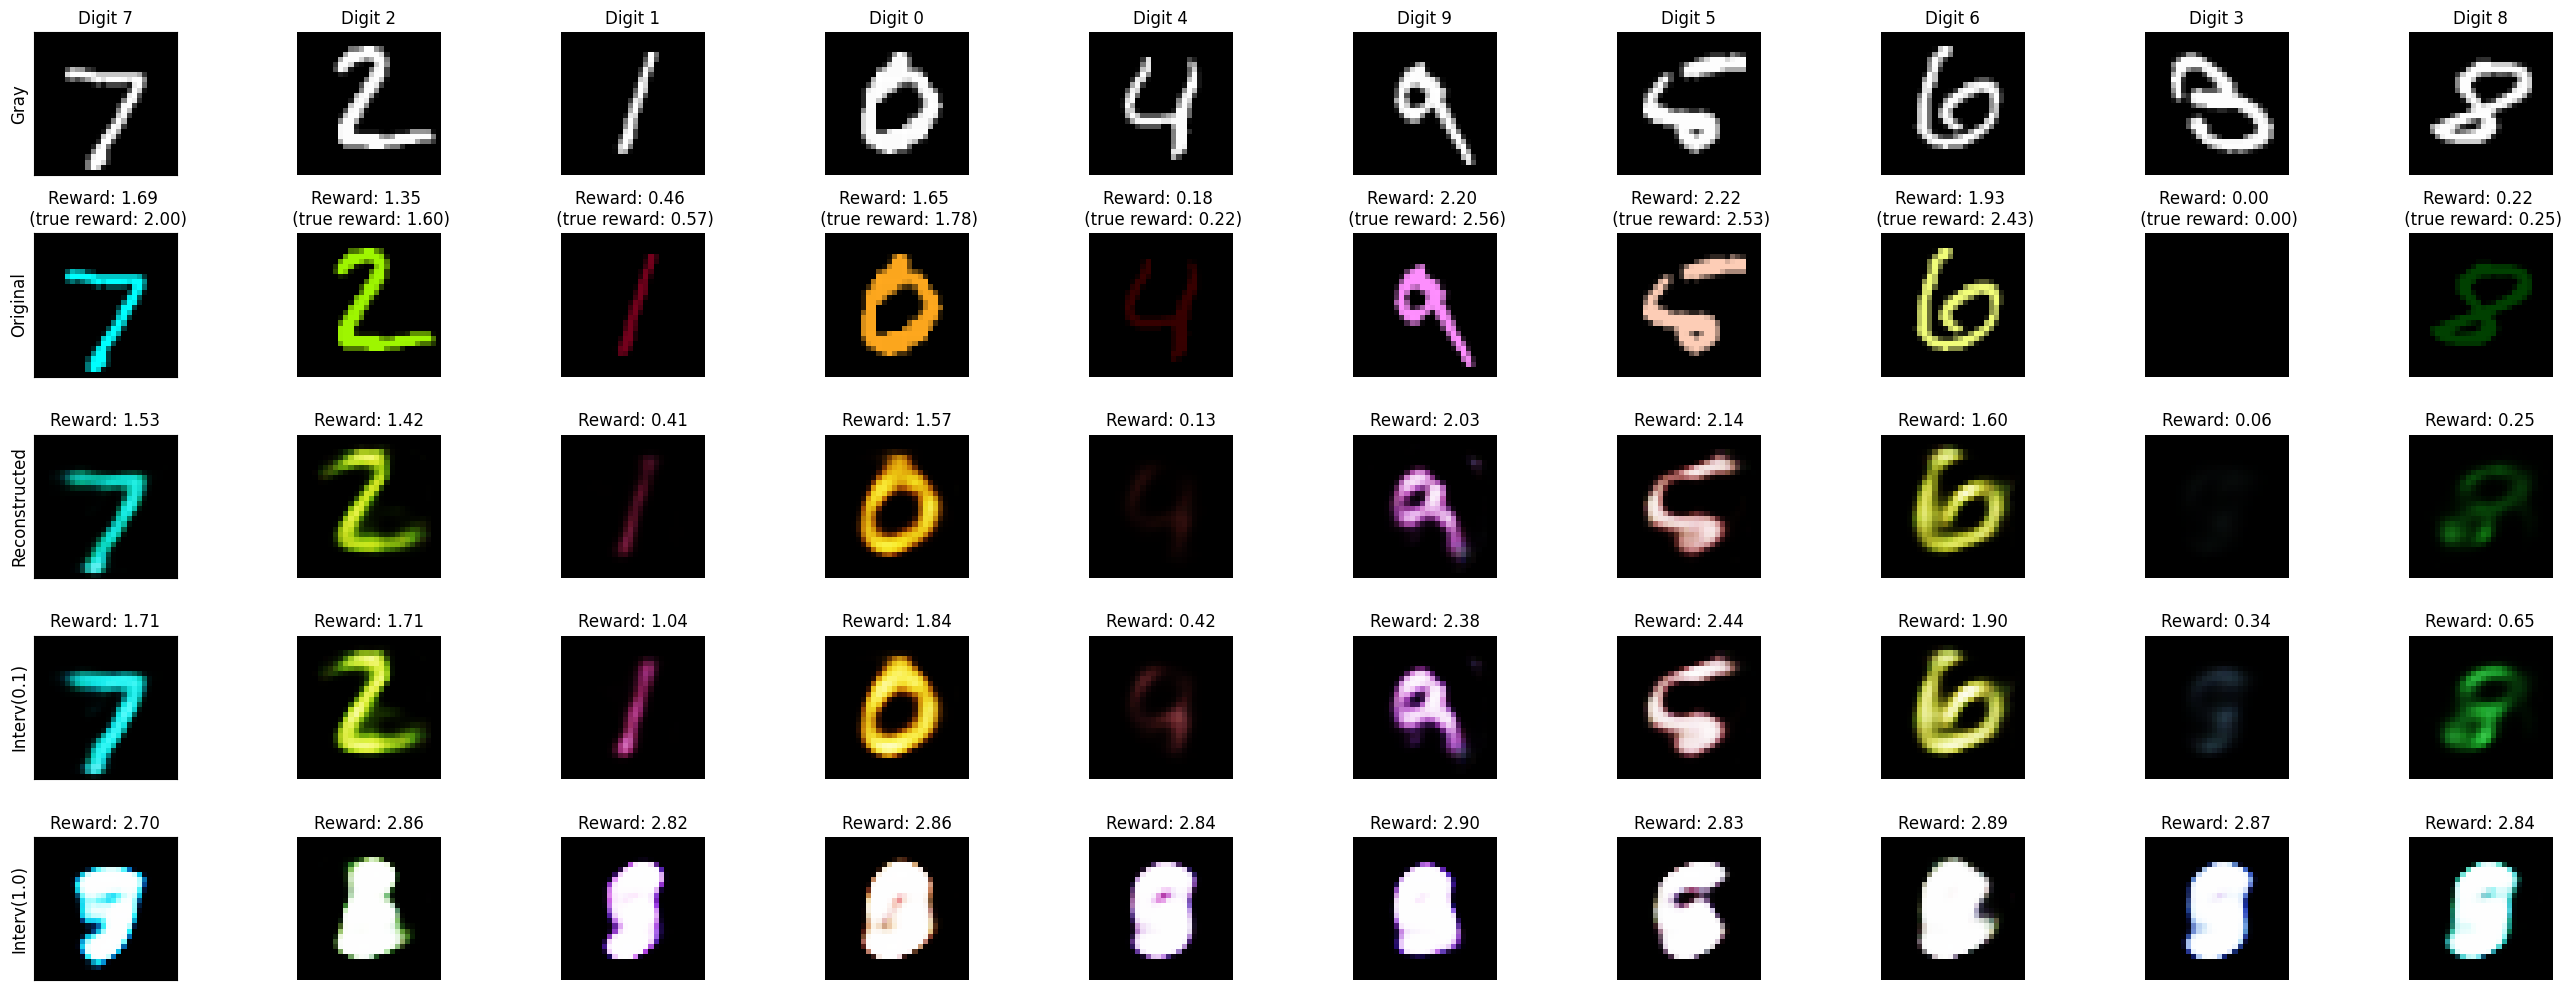

In [17]:
plot_examples(test_ds, ae, u,  alpha1=0.1, figname="irae3examples.png")

[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    1.6s remaining:    1.6s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    1.6s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    1.6s remaining:    1.6s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    1.6s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    1.5s remaining:    1.5s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    1.6s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    1.6s finished


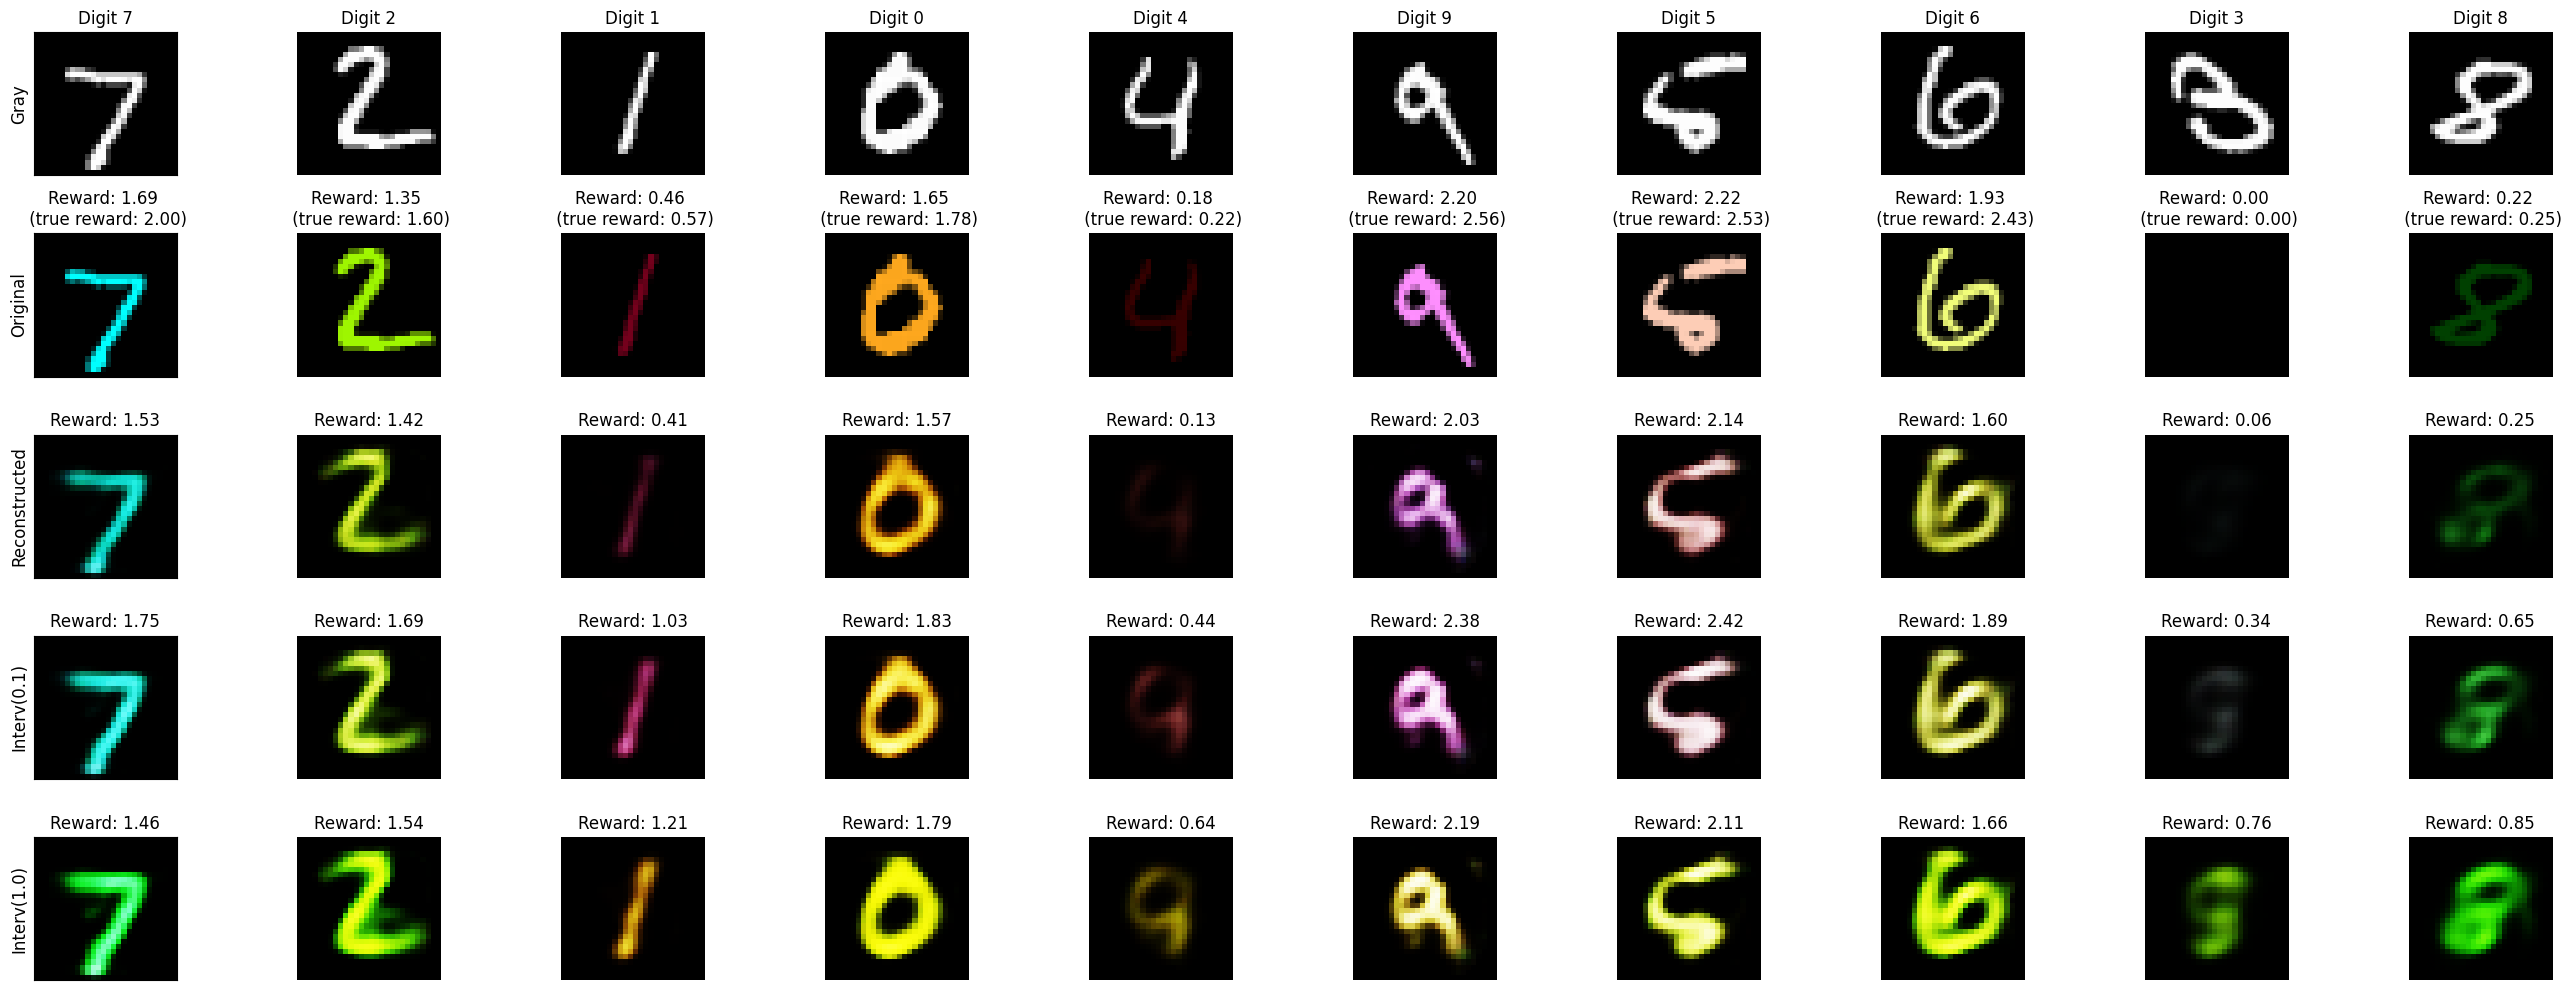

In [18]:
from utilities import safe_plot_examples
safe_plot_examples(test_ds, ae, u, train_ds=train_ds, safety='clip', k=10, alpha1=0.1)

[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    0.0s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    0.0s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    0.0s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    1.5s finished


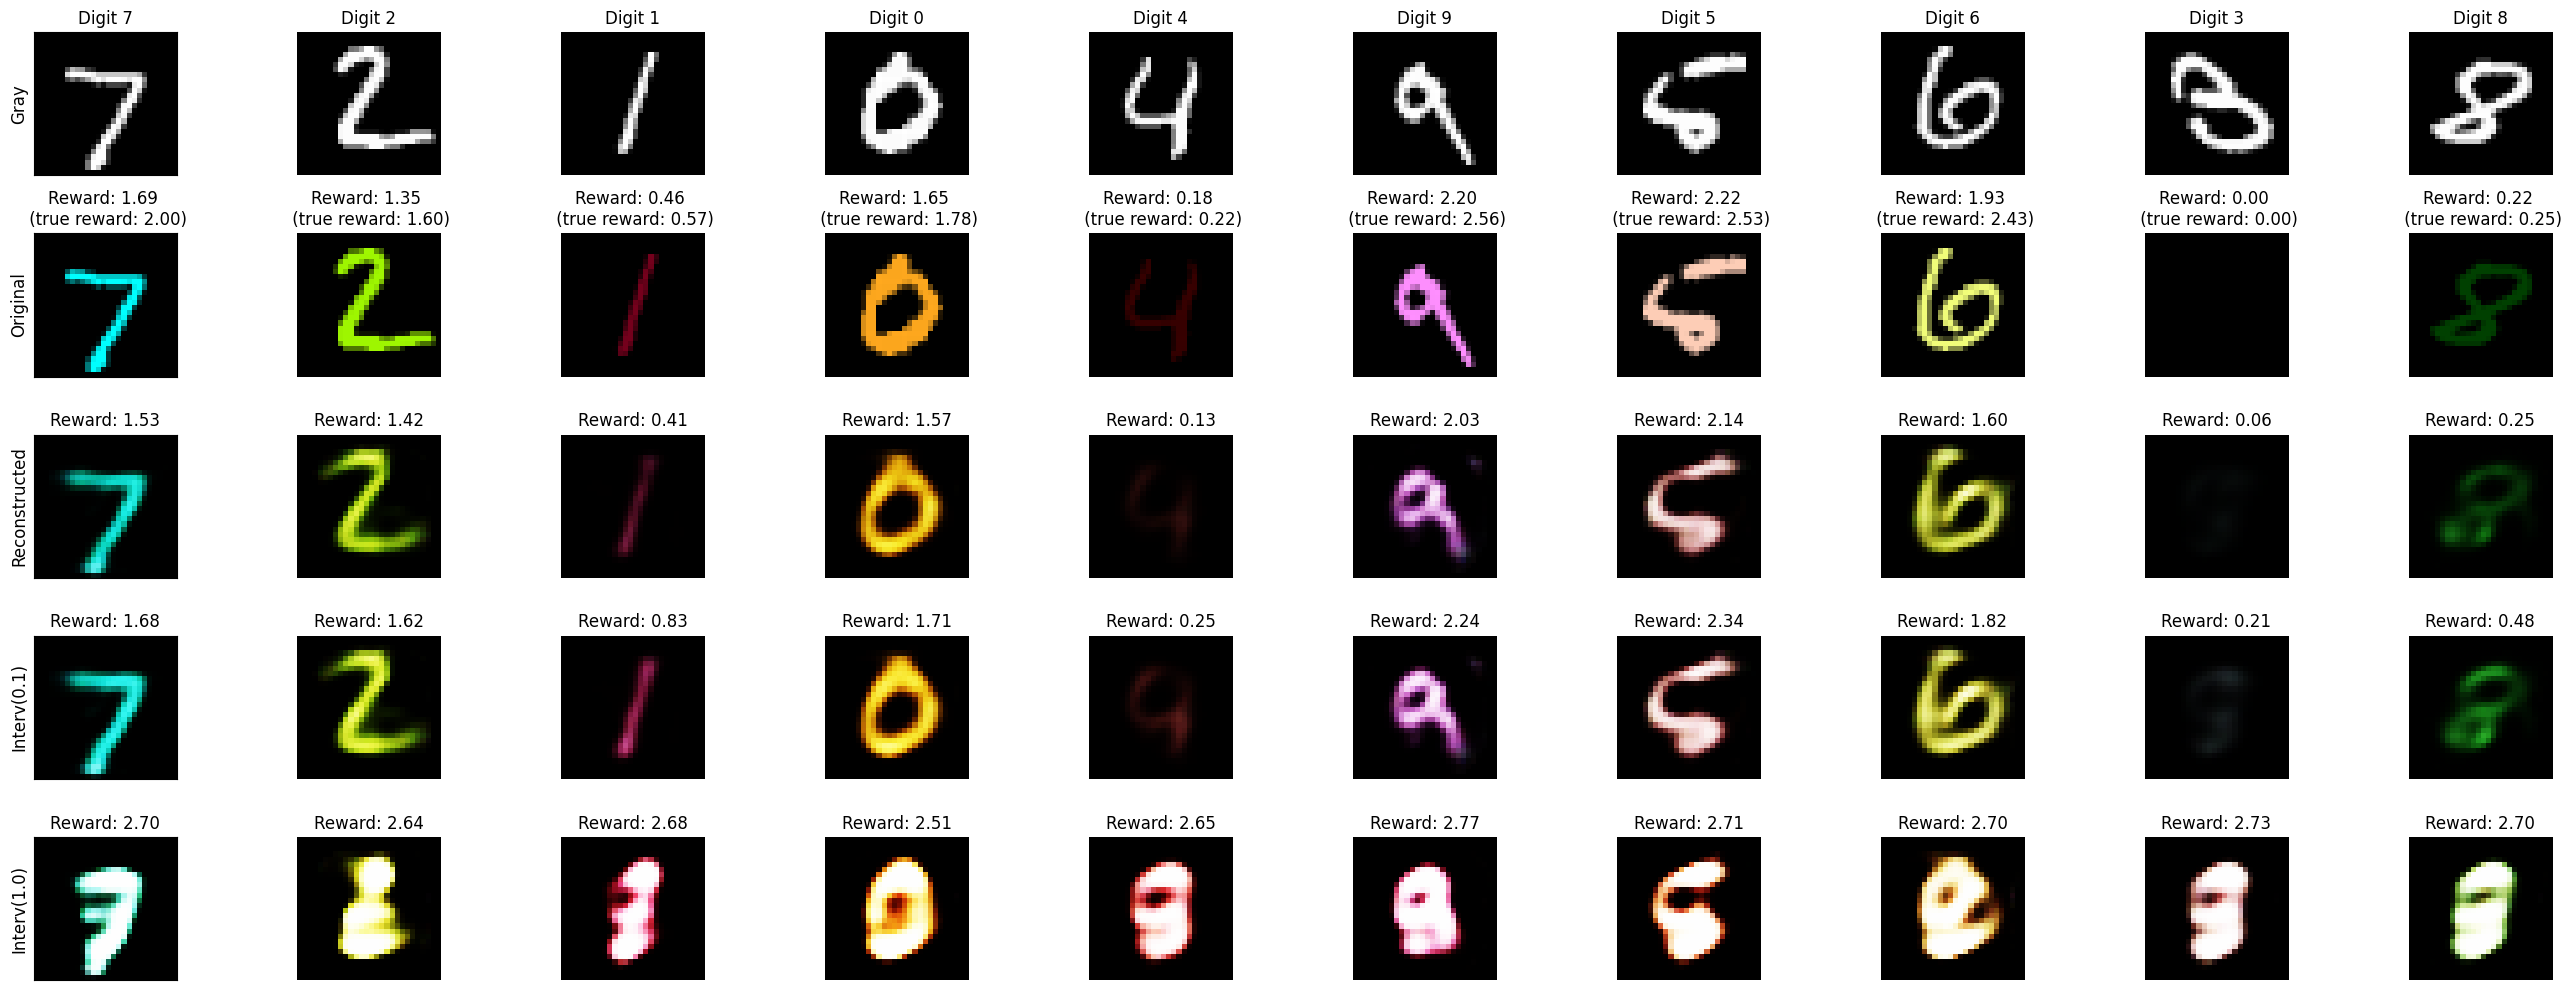

In [19]:
from utilities import safe_plot_examples
safe_plot_examples(test_ds, ae, u, train_ds=train_ds, safety='pca', n_components=30, alpha1=0.1)

[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    0.0s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    0.0s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    0.0s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    0.0s finished


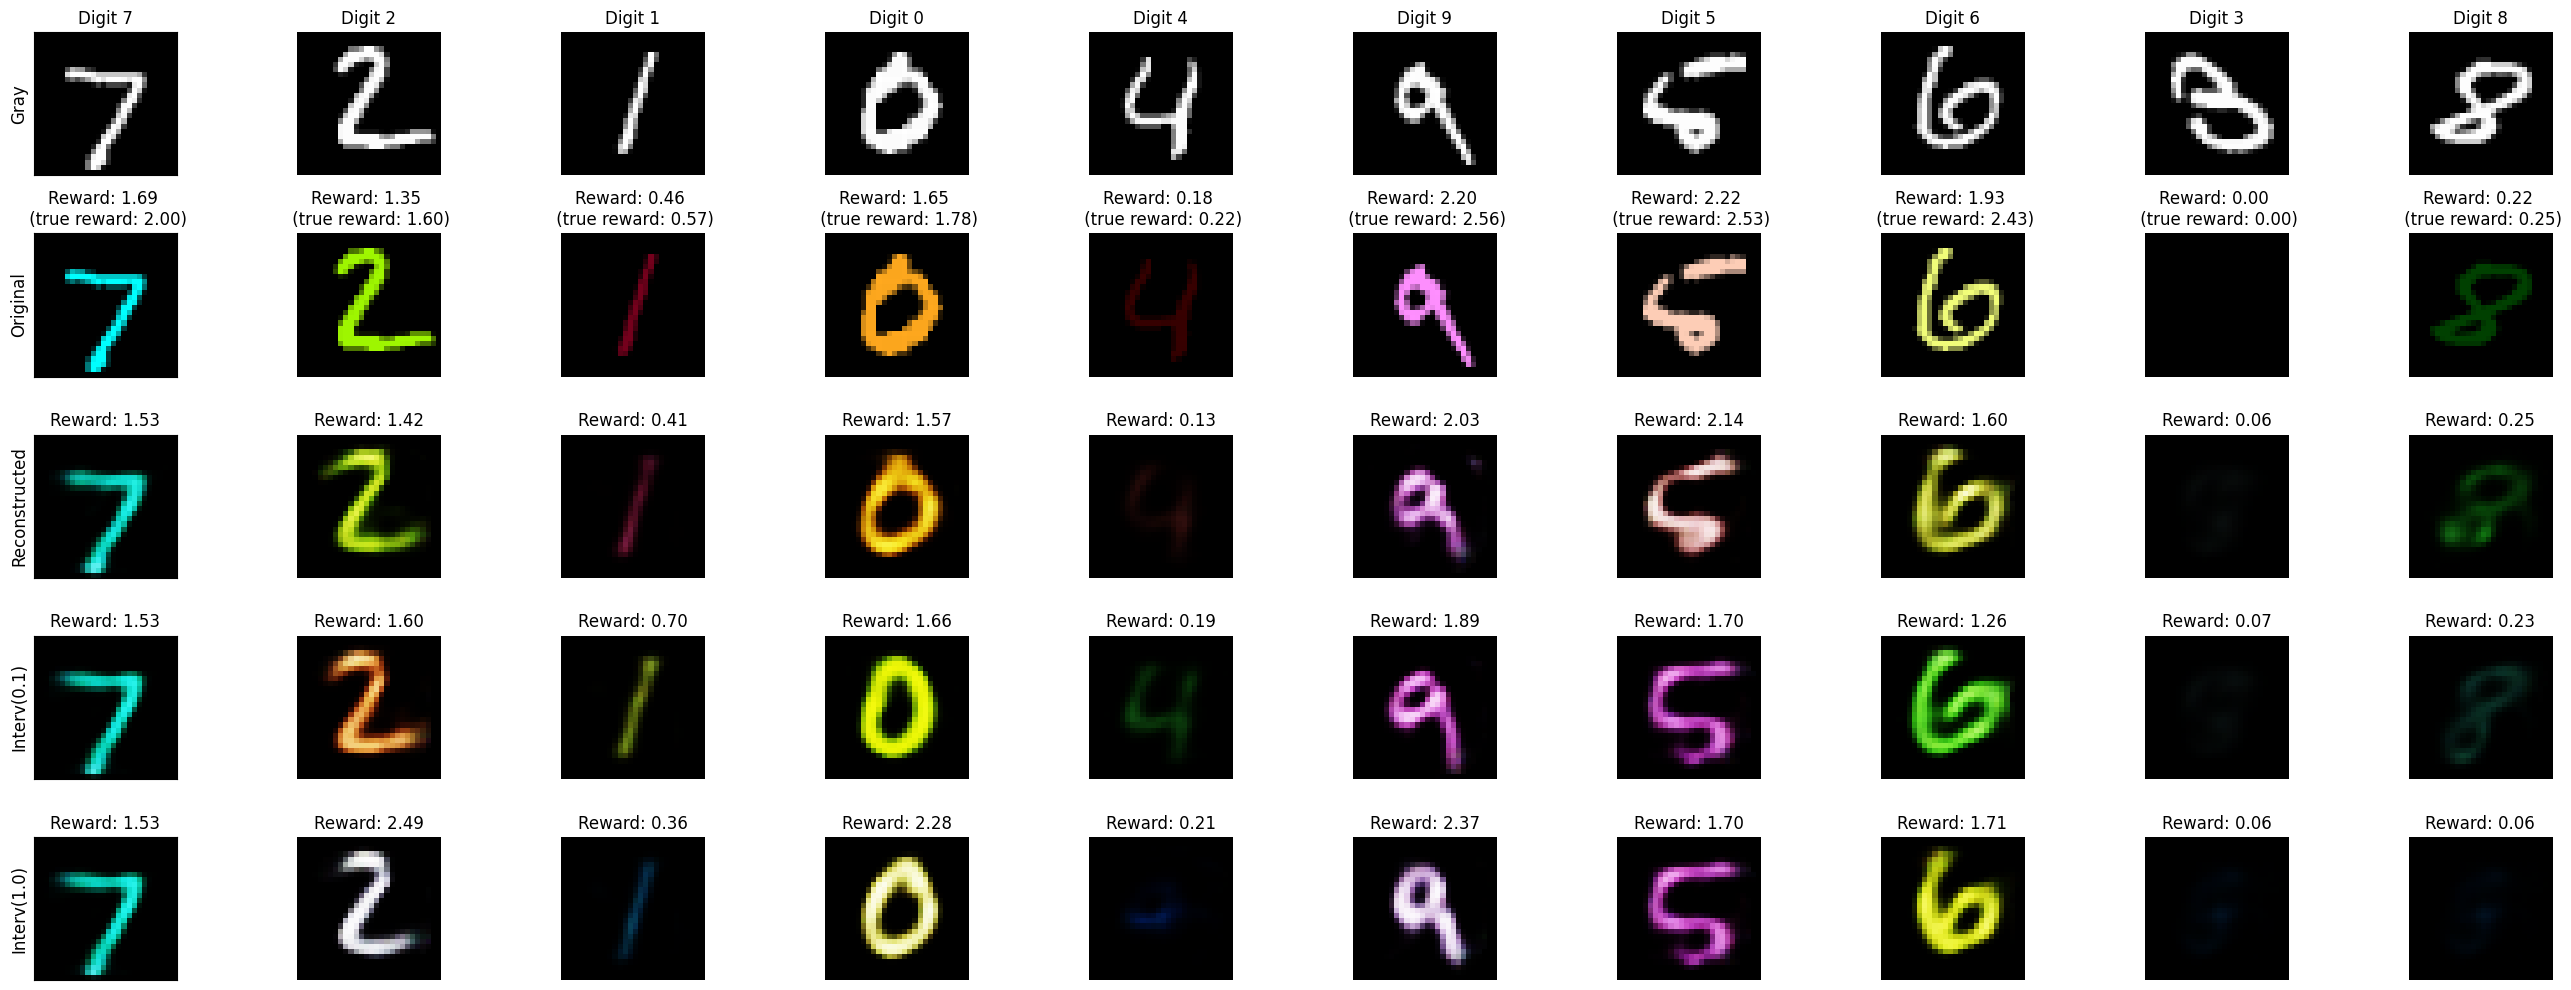

In [20]:
from utilities import safe_plot_examples
safe_plot_examples(test_ds, ae, u, train_ds=train_ds, safety='nearest', alpha1=0.1)

In [49]:
# what if we ignored confounding!
from sklearn.linear_model import LinearRegression

theta = LinearRegression().fit(D, Y).coef_
u_ols = theta / np.linalg.norm(theta)

[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    1.8s remaining:    1.8s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    1.8s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    1.6s remaining:    1.6s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    1.7s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    1.6s remaining:    1.6s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    1.6s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   5 out of  10 | elapsed:    1.6s remaining:    1.6s
[Parallel(n_jobs=75)]: Done  10 out of  10 | elapsed:    1.7s finished


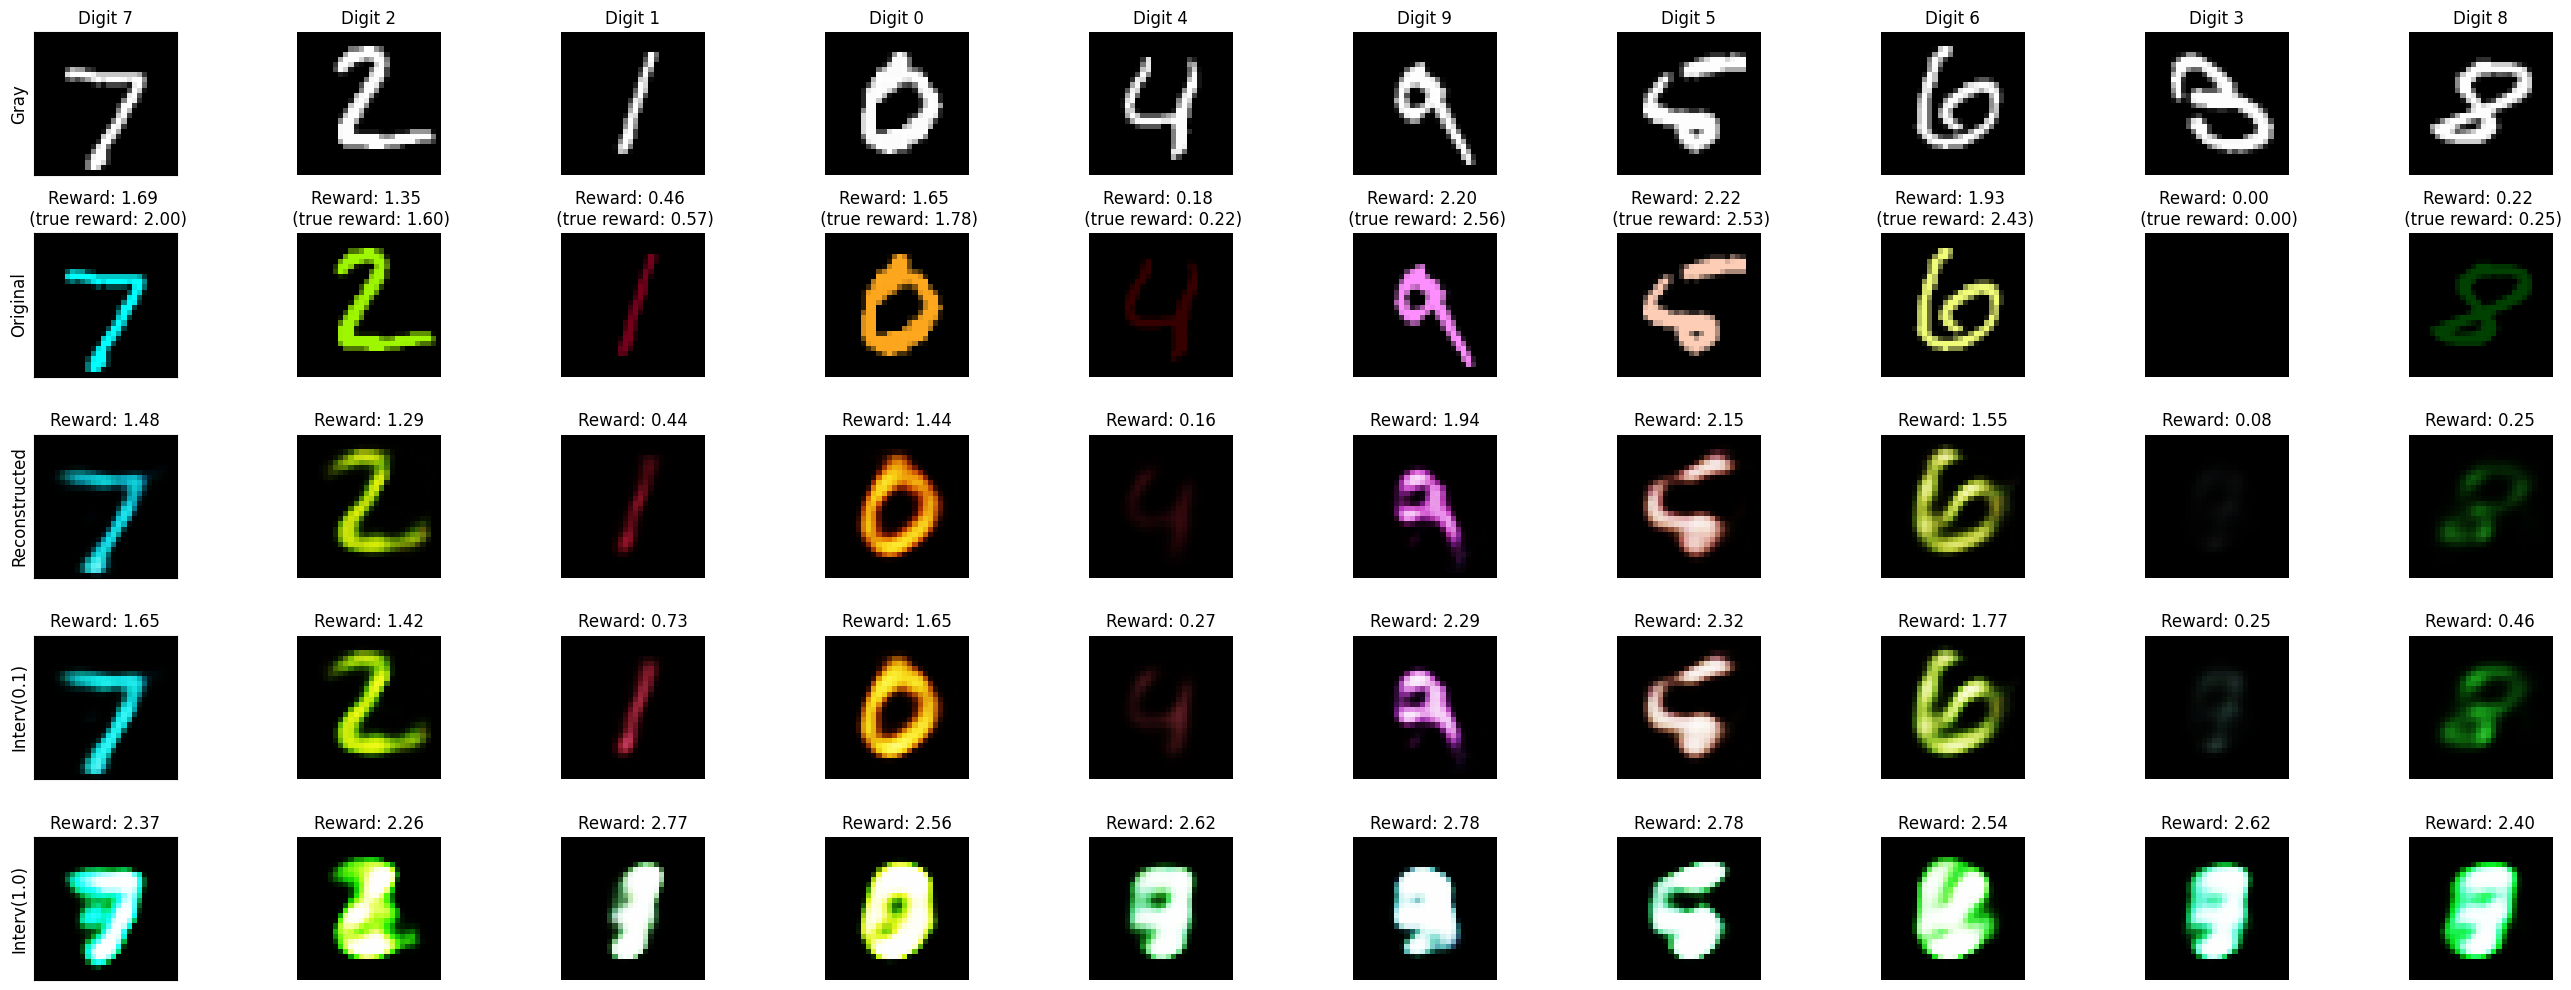

In [56]:
plot_examples(test_ds, ae, u_ols, alpha1=0.1, figname="irae3examples_ols.png")

In [51]:
perf_results = get_performance(test_ds, ae, u)
y_true, y_original, y_recon, y_interv, y_interv2 = perf_results
np.mean(y_true), np.mean(y_original), np.mean(y_recon), np.mean(y_interv), np.mean(y_interv2)

Generating interventional image data


[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done   1 out of   1 | elapsed:    0.0s finished
[Parallel(n_jobs=75)]: Done 160 tasks      | elapsed:    0.1s
[Parallel(n_jobs=75)]: Done 798 tasks      | elapsed:    0.1s
[Parallel(n_jobs=75)]: Done 3570 tasks      | elapsed:    0.3s
[Parallel(n_jobs=75)]: Done 9284 tasks      | elapsed:    0.5s
[Parallel(n_jobs=75)]: Done 9851 out of 10000 | elapsed:    0.5s remaining:    0.0s
[Parallel(n_jobs=75)]: Done 10000 out of 10000 | elapsed:    0.7s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done 138 tasks      | elapsed:    0.0s
[Parallel(n_jobs=75)]: Done 698 tasks      | elapsed:    0.1s
[Parallel(n_jobs=75)]: Done 3050 tasks      | elapsed:    0.2s
[Parallel(n_jobs=75)]: Done 8870 tasks      | elapsed:    0.4s
[Parallel(n_jobs=75)]: Done 10000 out of 10000 | elapsed:    0.5s finished
[Parallel(n_jobs=75)]: Using backend Loky

(np.float64(1.5024508775336667),
 np.float32(1.30712),
 np.float32(1.1775324),
 np.float32(1.5459185),
 np.float32(2.494415))

In [52]:
perf_results = get_performance(test_ds, ae, u, variant='max_intensity')
y_true, y_original, y_recon, y_interv, y_interv2 = perf_results
np.mean(y_true), np.mean(y_original), np.mean(y_recon), np.mean(y_interv), np.mean(y_interv2)

Generating interventional image data


(np.float64(1.5024508775336667),
 np.float32(1.5018562),
 np.float32(1.7635305),
 np.float32(2.263961),
 np.float32(2.9969864))

In [21]:
perf_results, perf_mi_results = get_performance(test_ds, ae, u, variant=['kmeans', 'max_intensity'])
y_true, y_original, y_recon, y_interv, y_interv2 = perf_results
print(np.mean(y_true), np.mean(y_original), np.mean(y_recon), np.mean(y_interv), np.mean(y_interv2))
y_true, y_original, y_recon, y_interv, y_interv2 = perf_mi_results
print(np.mean(y_true), np.mean(y_original), np.mean(y_recon), np.mean(y_interv), np.mean(y_interv2))

Generating interventional image data


[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done 138 tasks      | elapsed:    0.9s
[Parallel(n_jobs=75)]: Done 425 tasks      | elapsed:    1.2s
[Parallel(n_jobs=75)]: Done 1600 tasks      | elapsed:    1.3s
[Parallel(n_jobs=75)]: Done 8064 tasks      | elapsed:    1.7s
[Parallel(n_jobs=75)]: Done 10000 out of 10000 | elapsed:    1.8s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done 138 tasks      | elapsed:    0.0s
[Parallel(n_jobs=75)]: Done 698 tasks      | elapsed:    0.1s
[Parallel(n_jobs=75)]: Done 3050 tasks      | elapsed:    0.2s
[Parallel(n_jobs=75)]: Done 9180 tasks      | elapsed:    0.4s
[Parallel(n_jobs=75)]: Done 10000 out of 10000 | elapsed:    0.5s finished
[Parallel(n_jobs=75)]: Using backend LokyBackend with 75 concurrent workers.
[Parallel(n_jobs=75)]: Done 138 tasks      | elapsed:    0.0s
[Parallel(n_jobs=75)]: Done 698 tasks      | elapsed:    

1.5024508775336667 1.30712 1.1911436 1.8576106 2.8147738
1.5024508775336667 1.5018562 1.784853 2.677617 2.999998


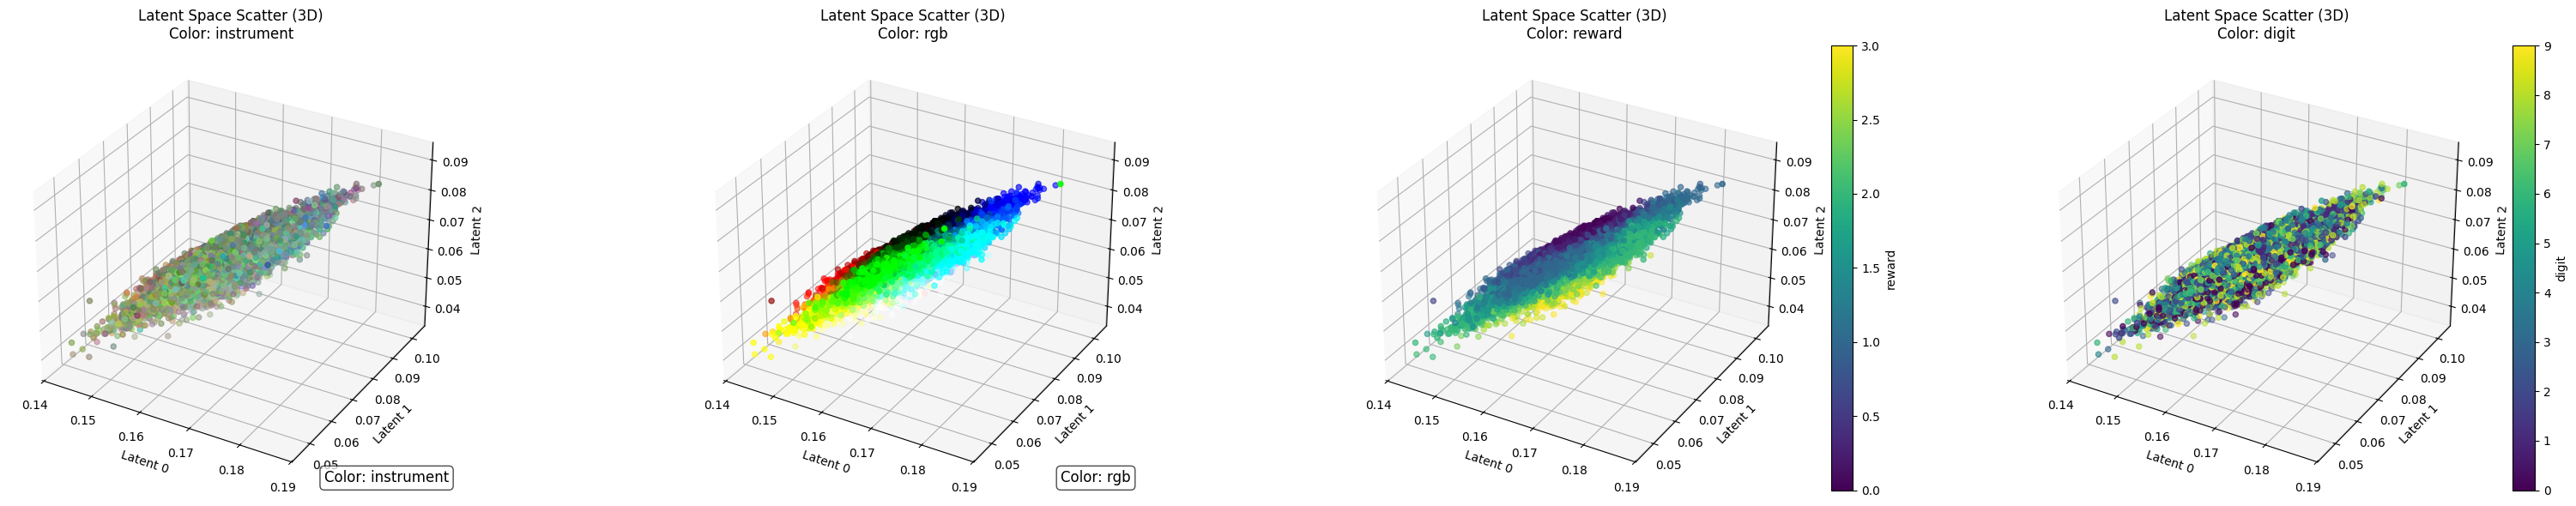

In [22]:
plot_latent_space_from_dataset(test_ds, ae, figname='latent_plot_irae3.png', color_variable=color_variable)

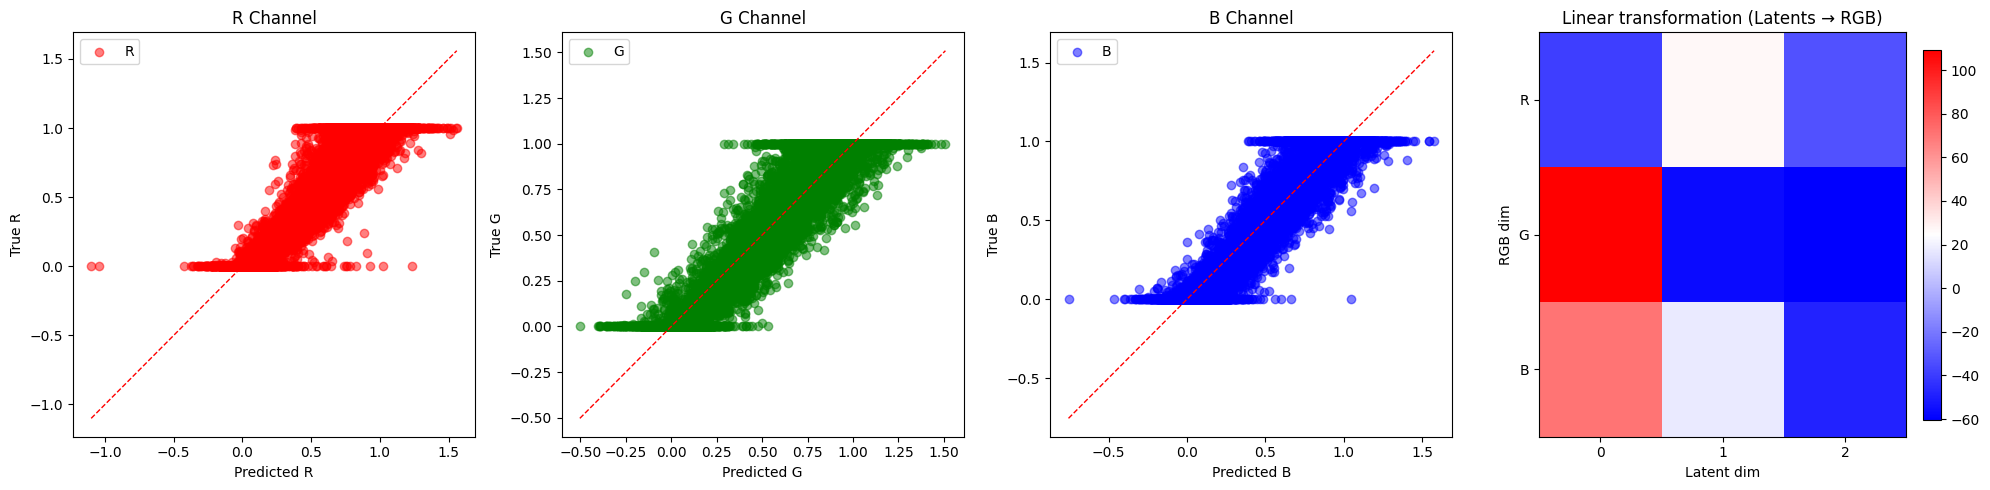

In [23]:
plot_linear_alignment_from_dataset(test_ds, ae, figname='latent_alignment_plot_irae3.png')